# Hospital Service Area (HSA) Delineation — Final

Runs all three algorithm variants in a single execution, producing three
independently versioned boundary bundles:

| Bundle | Algorithm features | Output suffix |
|--------|--------------------|---------------|
| **v6** | Greedy optimization only (no post-selection corrections) | `_v6` |
| **v7** | + Anchor upgrade/demotion + Major-orphan promotion | `_v7` |
| **v8** | + Satellite bubble boundaries | `_v8` |

All five optimization modes (FEWEST, FOOTPRINT, DISTANCE, GOVERNORATE_TAU_COVERAGE,
GOVERNORATE_FEWEST) run for each algorithm variant.  Output files are written to
`out/` and are named `{NETWORK}_{mode}_hsas_{variant}.geojson`.

Downstream notebooks select a specific bundle via `BOUNDARY_VERSION = "v6" | "v7" | "v8"`.

See `HSA_V7_ALGORITHM_MODIFICATIONS_VS_MANUSCRIPT.md` for a detailed description
of the changes introduced in v7 and v8.


In [1]:
# ============================================================================
# COMPREHENSIVE CONFIGURATION - PARAMETERS ACTUALLY USED
# ============================================================================
# Cleaned configuration with ONLY parameters that are used in the code.
# Removed unused parameters: RNG_SEED, BUFFER_KM, COARSEN_FACTOR, VOLUME_WEIGHT,
# PATIENT_RADIUS_ALPHA, TARGET_HSA_MIN, TARGET_HSA_MAX, CLIMATE_CSV

from pathlib import Path
import os

# --- File Paths ---
#NETWORK = "INF" uncomment this if you don't want to skip step 1; if you uncomment this one, then comment the next line
NETWORK = "SYNMODINF"

DATA_DIR = Path(os.environ.get("HSA_DATA_DIR", "data"))
OUT_DIR  = Path(os.environ.get("HSA_OUT_DIR", os.environ.get("PIPELINE_OUT_DIR", "out")))
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Algorithm variant configuration ────────────────────────────────────
# Controls which post-greedy corrections and boundary enhancements run.
# Each variant is run in sequence; outputs are written with a _v6/_v7/_v8 suffix.
#
# Only v7 is reported, so only v7 is built by default. The v6 and v8 entries are
# retained below and can be re-enabled by adding them back to ALGORITHM_VARIANTS;
# running all three triples the delineation time.
_ALGORITHM_VARIANT_LIBRARY = {
    "v6": {
        "version": "v6",
        "label": "Greedy only (original algorithm)",
        "UPGRADE_WEAK_SELECTED_ANCHORS": False,
        "PROMOTE_MAJOR_UNCOVERED_FACILITIES": False,
        "ENABLE_SATELLITE_BUBBLE_HSAS": False,
    },
    "v7": {
        "version": "v7",
        "label": "Anchor upgrade/demotion + major-orphan promotion",
        "UPGRADE_WEAK_SELECTED_ANCHORS": True,
        "PROMOTE_MAJOR_UNCOVERED_FACILITIES": True,
        "ENABLE_SATELLITE_BUBBLE_HSAS": False,
    },
    "v8": {
        "version": "v8",
        "label": "Anchor quality-control + satellite bubble boundaries",
        "UPGRADE_WEAK_SELECTED_ANCHORS": True,
        "PROMOTE_MAJOR_UNCOVERED_FACILITIES": True,
        "ENABLE_SATELLITE_BUBBLE_HSAS": True,
    },
}

# Override with e.g. HSA_VARIANTS="v6,v7,v8" to rebuild the other bundles.
ALGORITHM_VARIANTS = [
    _ALGORITHM_VARIANT_LIBRARY[v.strip()]
    for v in os.environ.get("HSA_VARIANTS", "v7").split(",")
    if v.strip()
]

# --- Geographic Bounds ---
JORDAN_BOUNDS = [34.5, 29.0, 39.5, 33.5]  # [min_lon, min_lat, max_lon, max_lat]

# --- Core Algorithm Parameters ---
TAU_COVERAGE = 0.90                    # Maximum target coverage (used for governorate mode calculation)

# --- Density-Based Classification ---
DENSITY_RADIUS_KM = 10.0               # Radius for density calculation
URBAN_DENSITY_THRESH = 1500.0          # Urban if density > this (people/km²)

# --- Base Radii ---
URBAN_BASE_RADIUS_KM = 10.0            # Base radius for urban facilities
RURAL_BASE_RADIUS_KM = 18.0            # Base radius for rural facilities

# --- Network-Specific Multipliers ---
NETWORK_RADIUS_MULTIPLIERS = {
    'INF': 1.0,   # Infectious disease network
    'NCD': 1.0,   # Non-communicable disease network
}

# --- Climate Diversity (applies to ALL objectives) ---
CLIMATE_DIVERSITY_ON = True
CLIMATE_K = 8                          # Number of climate clusters
CLIMATE_MIN_PER_CLUSTER = 0            # Hard floor per climate bin (set 0 to disable)
CLIMATE_CLUSTER_COL = "climate_k"      # Column with precomputed cluster per facility

# --- Scoring Weights (0-10 scale, applied to normalized 0-1 components) ---
# These are the baseline weights, modified by mode-specific profiles below
WEIGHT_COVERAGE = 8.0                  # Population coverage gain (DOMINANT factor)
WEIGHT_OVERLAP_PENALTY = 2.0           # Penalty for redundant coverage
WEIGHT_CLIMATE = 1.0                   # Reward for climate/geographic diversity
WEIGHT_PATIENT_VOLUME = 3.0            # Reward for larger patient volumes
WEIGHT_COVERAGE_PROGRESS = 1.0         # Reward for approaching coverage target
WEIGHT_DISTANCE_PENALTY = 3.0          # Penalty for average travel distance


# --- Post-Processing Thresholds ---
OVERLAP_REMOVAL_THRESHOLD = 0.80           # Remove HSAs with >80% overlap

# --- Major-Orphan Anchor Promotion ---
# After initial HSA selection, large uncovered facilities are promoted to anchors
# instead of being absorbed by distant nearest-HSA fallbacks during allocation.
MAJOR_FACILITY_POP_THRESHOLD = 25000.0
MAJOR_FACILITY_VOLUME_QUANTILE = 0.80
MAJOR_FACILITY_VOLUME_THRESHOLD = None
# A hospital qualifies as major on type alone; this floor keeps a near-idle
# facility from being promoted for its name. 0.50 = the network's median caseload.
HOSPITAL_MIN_VOLUME_QUANTILE = 0.50
ORPHAN_FALLBACK_RADIUS_MULTIPLIER = 1.5
ORPHAN_FALLBACK_MIN_DISTANCE_KM = 30.0
REQUIRE_SAME_GOVERNORATE_FOR_MAJOR_FALLBACK = True

# --- Anchor Upgrade / Demotion ---
# Before writing final HSA polygons, replace a weak selected anchor with a
# stronger nearby facility in the same local service area. Example: a small
# comprehensive center can be demoted to a normal facility if a much larger
# same-area hospital is a better HSA anchor.
ANCHOR_UPGRADE_SEARCH_RADIUS_MULTIPLIER = 1.0
ANCHOR_UPGRADE_MIN_VOLUME_RATIO = 2.0
ANCHOR_UPGRADE_MIN_ABSOLUTE_VOLUME_GAIN = 100.0
ANCHOR_UPGRADE_REQUIRE_SAME_GOVERNORATE = True

# --- Order-of-Operations Safeguards ---
# Anchor upgrade and major-facility promotion edit the anchor set *after* the
# optimizer has pruned overlapping HSAs, and an upgraded anchor inherits the
# radius fitted to the facility it replaces. Without these safeguards a
# relocated circle can land on top of a neighbouring anchor that was pruned
# against the original location, producing two near-identical HSAs.
ENFORCE_RELOCATION_OVERLAP_GUARD = True   # Step 3: reject upgrades that collide with another anchor
RUN_FINAL_OVERLAP_REMOVAL = True          # Step 5: prune overlaps over the completed anchor set
PROTECT_ORIGINAL_ANCHORS_IN_FINAL_PRUNE = True  # relocated/promoted anchors yield to in-place ones
SYMMETRIC_FINAL_OVERLAP_CHECK = True      # flag a pair when EITHER circle swallows the other
                                          # (the in-optimizer pass only tests one direction, so a
                                          #  small anchor whose circle contains a larger neighbour
                                          #  was never caught)
REPAIR_COVERAGE_AFTER_FINAL_PRUNE = True  # Step 6: restore target coverage lost to the final prune
COVERAGE_REPAIR_MAX_ADDITIONS = 10

# --- Satellite Bubble HSA Boundaries (v8) ---
# Build final HSA polygons as the primary anchor catchment plus smaller
# secondary catchment bubbles around eligible satellite facilities inside
# that HSA. Only bubbles that extend the primary boundary are unioned.
SATELLITE_BUBBLE_RADIUS_FRACTION = 0.35
SATELLITE_BUBBLE_MIN_RADIUS_KM = 2.0
SATELLITE_BUBBLE_MAX_RADIUS_KM = 6.0
SATELLITE_BUBBLE_REQUIRE_SAME_GOVERNORATE = True
SATELLITE_BUBBLE_REQUIRE_NEAREST_ANCHOR = True
SATELLITE_BUBBLE_BOUNDARY_ONLY = True
SATELLITE_BUBBLE_MIN_VOLUME = 0.0
SATELLITE_BUBBLE_MAX_PER_HSA = None


# --- Mode-Specific Weight Profiles ---
# Each mode applies multipliers to the base weights above
# The optimization stops when target coverage is reached - NO artificial facility count limits

MODE_WEIGHT_PROFILES = {
      'fewest': {
          'coverage': 15.0,          # Pure efficiency - maximize coverage per facility
          'coverage_progress': 0.0,
          'overlap': 0.1,
          'patient_volume': 0.0,     # CRITICAL: Not relevant to HSA coverage efficiency
          'climate': 0.0,
          'distance': 0.0,
      },
      'footprint': {
          'coverage': 0.8,          # Minimal efficiency preference
          'coverage_progress': 0.0,
          'overlap': 0.01,
          'patient_volume': 0.0,
          'climate': 1.2,            # Main driver - geographic diversity
          'distance': 0.0,
      },
      'distance': {
          'coverage': 0.5,
          'coverage_progress': 0.0,
          'overlap': 0.20,
          'patient_volume': 0.0,
          'climate': 0.05,
          'distance': 8.0,
      },
}

# --- Optimization Modes to Run ---
RUN_OBJECTIVES = {
    'fewest': True,                      # Minimize number of HSAs
    'footprint': True,                   # Maximize geographic spread
    'distance': True,                    # Minimize travel distance
    'governorate_tau_coverage': True,    # TAU method per governorate
    'governorate_fewest': True           # One anchor per governorate + FEWEST
}

# --- HSAOptimizer configuration dict ---
config = {
    'pop_path': str(DATA_DIR / 'jor_ppp_2020_UNadj.tif'),  # Population raster (10M version)
    'tau_coverage': 0.90,  # Used for GOVERNORATE_TAU_COVERAGE mode (90% per governorate)
    'coarsen': 4,  # Use FULL resolution (no coarsening) to preserve all 10.2M population. Or 4 to make it 4x faster
}

print("="*80)
print("CONFIGURATION LOADED")
print("="*80)
print(f"Network: {NETWORK}")
print(f"Main modes target coverage: {TAU_COVERAGE*100:.0f}%")
print(f"Governorate mode coverage: {config['tau_coverage']*100:.0f}%")
print(f"Coarsen factor: {config['coarsen']}x (full resolution)")
print(f"Urban base radius: {URBAN_BASE_RADIUS_KM} km")
print(f"Rural base radius: {RURAL_BASE_RADIUS_KM} km")
print(f"Climate diversity: {CLIMATE_DIVERSITY_ON}")
for _v in ALGORITHM_VARIANTS:
    print(f"  {_v['version']}: promote_major={_v['PROMOTE_MAJOR_UNCOVERED_FACILITIES']}, upgrade_anchors={_v['UPGRADE_WEAK_SELECTED_ANCHORS']}, satellite_bubbles={_v['ENABLE_SATELLITE_BUBBLE_HSAS']}")
print(f"Overlap threshold: {OVERLAP_REMOVAL_THRESHOLD:.2f}  "
      f"(relocation guard={ENFORCE_RELOCATION_OVERLAP_GUARD}, "
      f"final removal={RUN_FINAL_OVERLAP_REMOVAL}, "
      f"coverage repair={REPAIR_COVERAGE_AFTER_FINAL_PRUNE})")
print(f"Optimization is score-driven, with major uncovered facilities promoted after selection")
print("="*80)

CONFIGURATION LOADED
Network: SYNMODINF
Main modes target coverage: 90%
Governorate mode coverage: 90%
Coarsen factor: 4x (full resolution)
Urban base radius: 10.0 km
Rural base radius: 18.0 km
Climate diversity: True
  v7: promote_major=True, upgrade_anchors=True, satellite_bubbles=False
Overlap threshold: 0.80  (relocation guard=True, final removal=True, coverage repair=True)
Optimization is score-driven, with major uncovered facilities promoted after selection


In [2]:
# Generate diagnosis counts for the selected network
import sys
import subprocess

# Diagnosis counts path resolution: mode-aware when available, safe fallback when not.
mode_suffix = f"_{HSA_MODE}" if 'HSA_MODE' in globals() and HSA_MODE else ""
diag_candidates = []
if mode_suffix:
    diag_candidates.append(OUT_DIR / f'{NETWORK}{mode_suffix}_diagnosis_counts_pivot.csv')
diag_candidates.extend([
    OUT_DIR / f'{NETWORK}_diagnosis_counts_pivot.csv',
    OUT_DIR / f'{NETWORK}_footprint_diagnosis_counts_pivot.csv',
])

diag_csv = next((c for c in diag_candidates if c.exists()), diag_candidates[0])
def _resolve(prefix, suffix):
    real = DATA_DIR / f'{prefix}_{suffix}'
    if real.exists(): return real
    synmod = DATA_DIR / f'SYNMOD{prefix}_{suffix}'
    if synmod.exists(): return synmod
    raise FileNotFoundError(f'{real.name} not found in {DATA_DIR} (also tried SYNMOD prefix)')

groups_csv  = _resolve(NETWORK, 'groups_of_diagnoses.csv')
patients_csv = _resolve(NETWORK, 'patient_visits.csv')

print(f'Preparing diagnosis counts for {NETWORK}...')
result = subprocess.run([sys.executable, 'generate_diagnosis_counts_v2.py', '--networks', NETWORK, '--out-dir', str(OUT_DIR)], check=False)
if result.returncode != 0:
    raise RuntimeError(f'Diagnosis counts generation failed (code {result.returncode}).')
# Re-evaluate candidates after generation — the pre-run check may have defaulted to the wrong name
diag_csv = next((c for c in diag_candidates if c.exists()), diag_candidates[0])
if not diag_csv.exists():
    raise FileNotFoundError(f'Diagnosis counts not found after generation: {diag_csv}')
print(f'✓ Diagnosis counts ready: {diag_csv}')


Preparing diagnosis counts for SYNMODINF...
GENERATE DIAGNOSIS COUNTS FROM AUTHORITATIVE FACILITIES (V2)
Networks: SYNMODINF

PROCESSING SYNMODINF NETWORK

Loading authoritative facilities: SYNMODINF_facility_coordinates.csv
  Loaded 188 authoritative facilities
  Unique governorates: 12

Loading diagnosis groups: SYNMODINF_groups_of_diagnoses.csv
  Loaded 157 diagnosis mappings
  Unique groups: 15

Loading patient data: SYNMODINF_patient_visits.csv
  Total records: 66,876
  Unique patients: 66,876
  Unique facility-governorate pairs: 188

Matching patient data to authoritative facilities...

  Records matched to authoritative: 66,876 (100.0%)
  Records NOT in authoritative: 0
  Discrepancy types found: 0

Assigning diagnosis groups...
  Diagnoses with groups: 66,876 (100.0%)

Deduplicating diagnoses...
  Original diagnoses: 66,876
  Duplicates removed: 0 (0.0%)
  Unique diagnoses: 66,876

Creating diagnosis count tables...
  [OK] Saved: SYNMODINF_footprint_diagnosis_counts_total.csv (

In [3]:
%load_ext autoreload
%autoreload 2


# ============================================================================
# IMPORTS AND PARAMETER INJECTION
# ============================================================================

# Import libraries
import sys
from pathlib import Path
import geopandas as gpd
import pandas as pd

# Import optimization module
import hsa_optimization
from hsa_optimization import HSAOptimizer

# ============================================================================
# INJECT CONFIGURATION INTO HSA_OPTIMIZATION MODULE
# ============================================================================
# The hsa_optimization module no longer defines its own parameters.
# Instead, it expects them to be injected from the notebook.
# This makes all parameters visible and editable in one place (Cell 1 above).

param_names = [
      'DATA_DIR', 'OUT_DIR', 'NETWORK',
      'TAU_COVERAGE',
      'DENSITY_RADIUS_KM', 'URBAN_DENSITY_THRESH',
      'URBAN_BASE_RADIUS_KM', 'RURAL_BASE_RADIUS_KM',
      'NETWORK_RADIUS_MULTIPLIERS',
      'CLIMATE_DIVERSITY_ON', 'CLIMATE_K', 'CLIMATE_MIN_PER_CLUSTER',
      'CLIMATE_CLUSTER_COL',
      'WEIGHT_COVERAGE', 'WEIGHT_OVERLAP_PENALTY', 'WEIGHT_CLIMATE',
      'WEIGHT_PATIENT_VOLUME', 'WEIGHT_COVERAGE_PROGRESS', 'WEIGHT_DISTANCE_PENALTY',
      'MODE_WEIGHT_PROFILES',
      'JORDAN_BOUNDS', 'OVERLAP_REMOVAL_THRESHOLD',  # Added new parameters
]


print("Injecting parameters into hsa_optimization module...")
injected_count = 0
for param in param_names:
    if param in globals():
        setattr(hsa_optimization, param, globals()[param])
        injected_count += 1
    else:
        print(f"  WARNING: Parameter {param} not found in globals()")

print("="*80)
print("IMPORTS AND PARAMETER INJECTION COMPLETE")
print("="*80)
print(f"Parameters injected: {injected_count}/{len(param_names)}")
print("="*80)

HSAOptimizer.optimize method updated with governorate support
Governorate optimization methods added to HSAOptimizer class (tau_coverage and fewest)
create_hsa_polygons function defined
clip_hsas_to_country function defined
clip_hsas_to_population function defined
assign_adaptive_radii function defined
[OK] Professional mapping functions loaded
Injecting parameters into hsa_optimization module...
IMPORTS AND PARAMETER INJECTION COMPLETE
Parameters injected: 22/22


## Run Optimizations

Runs all enabled optimization modes (configured in Cell 1 via `RUN_OBJECTIVES`).

Results saved to GeoJSON files in the `out_v8/` directory by default; override with `HSA_OUT_DIR` or `PIPELINE_OUT_DIR`.

In [4]:
# ============================================================
# OUTER LOOP: Run all three algorithm variants in sequence
# ============================================================
all_version_results = {}   # keyed by (ALGO_VERSION, objective)

for _variant in ALGORITHM_VARIANTS:
    ALGO_VERSION = _variant['version']
    UPGRADE_WEAK_SELECTED_ANCHORS      = _variant['UPGRADE_WEAK_SELECTED_ANCHORS']
    PROMOTE_MAJOR_UNCOVERED_FACILITIES = _variant['PROMOTE_MAJOR_UNCOVERED_FACILITIES']
    ENABLE_SATELLITE_BUBBLE_HSAS       = _variant['ENABLE_SATELLITE_BUBBLE_HSAS']

    print(f"\n{'#'*80}")
    print(f"ALGORITHM VARIANT: {ALGO_VERSION} — {_variant['label']}")
    print(f"{'#'*80}\n")

    # Initialize optimizer
    optimizer = HSAOptimizer(config)
    
    
    
    # Load facilities WITH CLIMATE DATA from CSV
    # Facility climate is a shared input produced once by GEE Step A, before any
    # delineation exists. Look in the run directory first, then out/, then data/ --
    # the synthetic networks ship it there so the pipeline runs without an Earth
    # Engine account. These features depend only on facility location.
    climate_csv = OUT_DIR / f'{NETWORK}_Facilities_Climate_Features_with_clusters.csv'
    if not climate_csv.exists():
        for _alt in (Path('out') / climate_csv.name, DATA_DIR / climate_csv.name):  # noqa: hardcode - out/ holds the canonical facility-climate master
            if _alt.exists():
                print(f"  Facility climate not in {OUT_DIR}; using {_alt}")
                climate_csv = _alt
                break
    
    if not climate_csv.exists():
        raise FileNotFoundError(f"Climate CSV not found: {climate_csv}")
    
    # Read climate CSV
    climate_df = pd.read_csv(climate_csv)
    
    # Rename FacilityName to HealthFacility (what the optimizer expects)
    if 'FacilityName' in climate_df.columns:
        climate_df['HealthFacility'] = climate_df['FacilityName']
    elif 'HealthFacility' not in climate_df.columns:
        raise ValueError("Climate CSV must have either 'FacilityName' or 'HealthFacility' column")
    
    # NORMALIZE WHITESPACE: Collapse multiple spaces to single space
    climate_df['HealthFacility'] = climate_df['HealthFacility'].str.replace(r'\s+', ' ', regex=True).str.strip()
    
    # Load diagnosis counts (for Total column)
    # Diagnosis counts path resolution: mode-aware when available, safe fallback when not.
    mode_suffix = f"_{HSA_MODE}" if 'HSA_MODE' in globals() and HSA_MODE else ""
    diag_candidates = []
    if mode_suffix:
        diag_candidates.append(OUT_DIR / f'{NETWORK}{mode_suffix}_diagnosis_counts_pivot.csv')
    diag_candidates.extend([
        OUT_DIR / f'{NETWORK}_diagnosis_counts_pivot.csv',
        OUT_DIR / f'{NETWORK}_footprint_diagnosis_counts_pivot.csv',
    ])
    
    diagnosis_csv = next((c for c in diag_candidates if c.exists()), diag_candidates[0])
    if not diagnosis_csv.exists():
        raise FileNotFoundError(f"Diagnosis counts not found: {diagnosis_csv}")
    
    diagnosis_df = pd.read_csv(diagnosis_csv)
    
    # NORMALIZE WHITESPACE in diagnosis data as well
    diagnosis_df['healthfacility'] = diagnosis_df['healthfacility'].str.replace(r'\s+', ' ', regex=True).str.strip()
    
    # Merge climate data with diagnosis counts and facility metadata on HealthFacility
    merge_cols = ['healthfacility', 'total_diagnoses']
    for optional_col in ['healthfacilitytype', 'governorate']:
        if optional_col in diagnosis_df.columns:
            merge_cols.append(optional_col)
    
    merged_df = climate_df.merge(
        diagnosis_df[merge_cols],
        left_on='HealthFacility',
        right_on='healthfacility',
        how='left'
    )
    
    # Rename total_diagnoses to Total (what the optimizer expects)
    merged_df['Total'] = merged_df['total_diagnoses']
    
    # Check for missing values
    missing_total = merged_df['Total'].isna().sum()
    if missing_total > 0:
        print(f"WARNING: {missing_total} facilities missing diagnosis counts")
        print(f"  Missing facilities:")
        missing_facilities = merged_df[merged_df['Total'].isna()]['HealthFacility'].tolist()
        for fac in missing_facilities[:10]:  # Show first 10
            print(f"    - {fac}")
        if len(missing_facilities) > 10:
            print(f"    ... and {len(missing_facilities) - 10} more")
        # Fill with 0
        merged_df['Total'] = merged_df['Total'].fillna(0)
    
    # Create GeoDataFrame from lat/lon
    facilities = gpd.GeoDataFrame(
        merged_df,
        geometry=gpd.points_from_xy(merged_df['lon'], merged_df['lat']),
        crs='EPSG:4326'
    )
    
    # Reproject to UTM for distance calculations (Jordan is in UTM zone 36N/37N)
    # Using a common Jordan projection: EPSG:32637 (UTM 37N)
    facilities = facilities.to_crs('EPSG:32637')
    
    print(f"\nMerged climate + diagnosis data:")
    print(f"  Facilities with climate data: {len(climate_df)}")
    print(f"  Facilities with diagnosis counts: {len(diagnosis_df)}")
    print(f"  Facilities after merge: {len(facilities)}")
    print(f"  Facilities with Total column: {facilities['Total'].notna().sum()}")
    print(f"  Facilities with Total > 0: {(facilities['Total'] > 0).sum()}")
    print(f"  Facilities with HealthFacility column: {'HealthFacility' in facilities.columns}")
    
    
    print(f"Loaded {len(facilities)} {NETWORK} facilities ")
    if 'climate_k' in facilities.columns:
        print(f"  climate_k column present: YES")
        print(f"  climate_k values: {sorted(facilities['climate_k'].dropna().unique())}")
    else:
        print(f"  climate_k column present: NO (climate diversity scoring will be disabled!)")
    
    # Load governorates for governorate modes
    gov_file = DATA_DIR / 'jordan_governorates.gpkg'
    governorates = gpd.read_file(gov_file) if (DATA_DIR / 'jordan_governorates.gpkg').exists() else None
    
    # Store results for all objectives
    all_results = {}
    
    # Run optimizations for selected objectives
    for objective in ['fewest', 'footprint', 'distance', 'governorate_tau_coverage', 'governorate_fewest']:
        if objective not in RUN_OBJECTIVES or not RUN_OBJECTIVES[objective]:
            print(f"\nSkipping {objective.upper()} optimization (disabled)")
            continue
        
        print(f"\n{'='*80}")
        print(f"Running {objective.upper()} optimization...")
        print('='*80)
        
        # Run optimization
        if objective in ['governorate_tau_coverage', 'governorate_fewest']:
            if governorates is None:
                print("  ERROR: Governorates file not found, skipping")
                continue
            result = optimizer.optimize(facilities, objective=objective, network_type=NETWORK, governorates_gdf=governorates)
        else:
            result = optimizer.optimize(facilities, objective=objective, network_type=NETWORK)
    
        
        selected_facilities = result['facilities']
        coverage_pct = result['coverage_pct']
    
        # ====================================================================
        # POST-GREEDY ANCHOR EDITS — steps 3-6 of the delineation sequence.
        #   1. greedy selection            ] inside optimizer.optimize()
        #   2. preliminary overlap removal ]
        #   3. anchor promotion/demotion   (guarded against relocation collisions)
        #   4. major-facility promotion
        #   5. final overlap removal over the completed anchor set
        #   6. coverage recompute + repair of any deficit step 5 introduced
        # Steps 5-6 exist because moving an anchor while preserving its radius
        # can create an overlap that did not exist when the original anchor was
        # evaluated in step 2.
        # ====================================================================
        # The governorate modes meet their coverage target per governorate, so a
        # national repair target does not apply to them; there the repair only
        # restores what the final overlap pass removed.
        is_governorate_mode = objective in ('governorate_tau_coverage', 'governorate_fewest')
        target_coverage = config['tau_coverage'] if is_governorate_mode else TAU_COVERAGE
    
        relocation_guard = None
        if UPGRADE_WEAK_SELECTED_ANCHORS and ENFORCE_RELOCATION_OVERLAP_GUARD:
            relocation_guard = hsa_optimization.make_relocation_overlap_guard(
                optimizer, overlap_threshold=OVERLAP_REMOVAL_THRESHOLD
            )
    
        if UPGRADE_WEAK_SELECTED_ANCHORS:
            selected_facilities, anchor_upgrade_audit = hsa_optimization.upgrade_selected_anchors_to_stronger_facilities(
                selected_facilities,
                facilities,
                search_radius_multiplier=ANCHOR_UPGRADE_SEARCH_RADIUS_MULTIPLIER,
                min_volume_ratio=ANCHOR_UPGRADE_MIN_VOLUME_RATIO,
                min_absolute_volume_gain=ANCHOR_UPGRADE_MIN_ABSOLUTE_VOLUME_GAIN,
                require_same_governorate=ANCHOR_UPGRADE_REQUIRE_SAME_GOVERNORATE,
                relocation_overlap_guard=relocation_guard,
                max_relocation_overlap=OVERLAP_REMOVAL_THRESHOLD,
            )
            upgrade_audit_file = OUT_DIR / f'{NETWORK}_{objective}_anchor_upgrade_audit_{ALGO_VERSION}.csv'
            anchor_upgrade_audit.to_csv(upgrade_audit_file, index=False)
            print(f"  Saved anchor upgrade audit: {upgrade_audit_file.name}")
            result['facilities'] = selected_facilities
    
        if PROMOTE_MAJOR_UNCOVERED_FACILITIES:
            selected_facilities, major_orphan_audit = hsa_optimization.promote_major_uncovered_facilities(
                selected_facilities,
                facilities,
                major_pop_threshold=MAJOR_FACILITY_POP_THRESHOLD,
                major_volume_quantile=MAJOR_FACILITY_VOLUME_QUANTILE,
                major_volume_threshold=MAJOR_FACILITY_VOLUME_THRESHOLD,
                hospital_min_volume_quantile=HOSPITAL_MIN_VOLUME_QUANTILE,
                fallback_radius_multiplier=ORPHAN_FALLBACK_RADIUS_MULTIPLIER,
                fallback_min_distance_km=ORPHAN_FALLBACK_MIN_DISTANCE_KM,
                require_same_governorate=REQUIRE_SAME_GOVERNORATE_FOR_MAJOR_FALLBACK,
            )
            audit_file = OUT_DIR / f'{NETWORK}_{objective}_major_orphan_anchor_audit_{ALGO_VERSION}.csv'
            major_orphan_audit.to_csv(audit_file, index=False)
            print(f"  Saved major-orphan anchor audit: {audit_file.name}")
            result['facilities'] = selected_facilities
    
        anchor_edits_ran = UPGRADE_WEAK_SELECTED_ANCHORS or PROMOTE_MAJOR_UNCOVERED_FACILITIES
        if anchor_edits_ran and RUN_FINAL_OVERLAP_REMOVAL:
            print(f"\n  Final overlap validation ({objective.upper()}, {ALGO_VERSION})...")
            selected_facilities, final_audits, final_stats = hsa_optimization.finalize_anchor_set(
                optimizer,
                selected_facilities,
                facilities,
                overlap_threshold=OVERLAP_REMOVAL_THRESHOLD,
                target_coverage=target_coverage,
                protect_original_anchors=PROTECT_ORIGINAL_ANCHORS_IN_FINAL_PRUNE,
                repair_coverage=REPAIR_COVERAGE_AFTER_FINAL_PRUNE,
                max_additions=COVERAGE_REPAIR_MAX_ADDITIONS,
                symmetric_overlap=SYMMETRIC_FINAL_OVERLAP_CHECK,
                restore_only=is_governorate_mode,
            )
            for audit_name, audit_df in final_audits.items():
                audit_path = OUT_DIR / f'{NETWORK}_{objective}_{audit_name}_{ALGO_VERSION}.csv'
                audit_df.to_csv(audit_path, index=False)
            coverage_pct = final_stats['coverage_pct_final']
            result['facilities'] = selected_facilities
            result['coverage_pct'] = coverage_pct
            result['finalization_stats'] = final_stats
            # Anchors added after the greedy pass (promoted, or added by the
            # coverage repair) never had hsa_population written, leaving the
            # column null for most anchors in some modes, and for every anchor
            # of the governorate-targeted mode.
            selected_facilities = hsa_optimization.recompute_hsa_population(
                optimizer, selected_facilities)
            result['facilities'] = selected_facilities

            if final_stats['residual_overlap_violations'] > 0:
                raise RuntimeError(
                    f"{objective}/{ALGO_VERSION}: {final_stats['residual_overlap_violations']} anchor "
                    f"pair(s) still exceed the {OVERLAP_REMOVAL_THRESHOLD:.0%} overlap threshold after "
                    f"finalization — see {NETWORK}_{objective}_residual_overlap_{ALGO_VERSION}.csv"
                )
        
        all_results[objective] = {
            'result': result,
            'facilities': selected_facilities,
            'coverage': coverage_pct
        }
        
        print(f"\n{'='*80}")
        print(f"{objective.upper()} OPTIMIZATION COMPLETE")
        print('='*80)
        print(f"Selected: {len(selected_facilities)} HSAs")
        print(f"Coverage: {coverage_pct:.1f}%")
        
        # ========================================================================
        # SAVE RESULTS TO GEOJSON (v2 files)
        # ========================================================================
        print(f"\nSaving results to GeoJSON...")
        
        # Add metadata
        selected_with_meta = selected_facilities.copy().reset_index(drop=True)
        selected_with_meta['network_type'] = NETWORK
        selected_with_meta['optimization_mode'] = objective
    
        # Create HSA boundary polygons from selected facilities.
        # v8 option: union the anchor radius with smaller satellite-facility
        # bubbles that extend the primary HSA boundary.
        if ENABLE_SATELLITE_BUBBLE_HSAS:
            hsas_polygons, satellite_bubble_audit = hsa_optimization.create_bubbled_hsa_polygons(
                selected_with_meta,
                facilities,
                satellite_radius_fraction=SATELLITE_BUBBLE_RADIUS_FRACTION,
                satellite_min_radius_km=SATELLITE_BUBBLE_MIN_RADIUS_KM,
                satellite_max_radius_km=SATELLITE_BUBBLE_MAX_RADIUS_KM,
                require_same_governorate=SATELLITE_BUBBLE_REQUIRE_SAME_GOVERNORATE,
                require_nearest_anchor=SATELLITE_BUBBLE_REQUIRE_NEAREST_ANCHOR,
                include_only_boundary_extending=SATELLITE_BUBBLE_BOUNDARY_ONLY,
                min_satellite_volume=SATELLITE_BUBBLE_MIN_VOLUME,
                max_satellites_per_hsa=SATELLITE_BUBBLE_MAX_PER_HSA,
            )
            satellite_bubble_audit_file = OUT_DIR / f'{NETWORK}_{objective}_satellite_bubble_audit_{ALGO_VERSION}.csv'
            satellite_bubble_audit.to_csv(satellite_bubble_audit_file, index=False)
            print(f"  Saved satellite bubble audit: {satellite_bubble_audit_file.name}")
        else:
            hsas_polygons = hsa_optimization.create_hsa_polygons(selected_with_meta)
            satellite_bubble_audit = pd.DataFrame()
    
        hsas_polygons = hsas_polygons.reset_index(drop=True)
        hsas_gdf = selected_with_meta.copy()
        for bubble_col in [
            'satellite_bubble_count',
            'satellite_bubble_area_added_km2',
            'satellite_bubble_radius_km',
            'satellite_bubble_facilities',
        ]:
            if bubble_col in hsas_polygons.columns:
                hsas_gdf[bubble_col] = hsas_polygons[bubble_col].values
        hsas_gdf['geometry'] = hsas_polygons.geometry.values
        
        # Clip HSA circles to WorldPop populated cells (removes uninhabited desert)
        print(f"  Clipping HSAs to populated WorldPop cells...")
        # Use constrained WorldPop for clipping: only assigns population where
        # buildings are detected, so true desert = 0 (UNadj spreads population
        # to all land cells including desert, preventing desert carve-outs)
        constrained_pop_path = DATA_DIR / 'jor_ppp_2020_constrained.tif'
        hsas_gdf = hsa_optimization.clip_hsas_to_population(
            hsas_gdf, str(constrained_pop_path), min_pop=0.0, coarsen=2,
            min_patch_km2=0.5, smooth_m=500
        )
    
        # Save to versioned GeoJSON file (suffix = algorithm variant)
        output_file = OUT_DIR / f'{NETWORK}_{objective}_hsas_{ALGO_VERSION}.geojson'
        hsas_gdf.to_file(output_file, driver='GeoJSON')
        
        # Verify saved file
        reloaded = gpd.read_file(output_file)
        print(f"  Saved: {output_file.name}")
        print(f"  Columns in saved file: {len(reloaded.columns)}")
        print(f"  climate_k preserved: {'climate_k' in reloaded.columns}")
        print(f"  satellite bubbles preserved: {'satellite_bubble_count' in reloaded.columns}")
        
        if 'service_radius_km' in reloaded.columns:
            max_radius = reloaded['service_radius_km'].max()
            print(f"  Max service_radius_km: {max_radius:.1f} km (should be <= 30.0)")
            if max_radius > 30.0:
                print(f"  WARNING: Radius exceeds 30 km limit!")
        
        print(f"  File verified successfully")
    
    print(f"\n\n{'='*80}")
    print("ALL OPTIMIZATIONS COMPLETE")
    print('='*80)
    for obj, data in all_results.items():
        print(f"  {obj.upper():26s}: {len(data['facilities']):3d} HSAs, {data['coverage']:.1f}% coverage")
    
    # Collect results indexed by version
    for obj, data in all_results.items():
        all_version_results[(ALGO_VERSION, obj)] = data

# ============================================================
print('\n\nALL ALGORITHM VARIANTS COMPLETE')
print('Output files written to:', OUT_DIR)
for (ver, obj), data in sorted(all_version_results.items()):
    n = len(data['facilities'])
    cov = data['coverage']
    print(f'  {ver}  {obj:30s}: {n:3d} HSAs, {cov:.1f}% coverage')



################################################################################
ALGORITHM VARIANT: v7 — Anchor upgrade/demotion + major-orphan promotion
################################################################################

  Facility climate not in out; using data/SYNMODINF_Facilities_Climate_Features_with_clusters.csv

Merged climate + diagnosis data:
  Facilities with climate data: 188
  Facilities with diagnosis counts: 188
  Facilities after merge: 188
  Facilities with Total column: 188
  Facilities with Total > 0: 188
  Facilities with HealthFacility column: True
Loaded 188 SYNMODINF facilities 
  climate_k column present: YES
  climate_k values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Running FEWEST optimization...

Running FEWEST optimization for SYNMODINF

Assigning radii for 188 SYNMODINF facilities...
  Computing local density within 10.0km radius...
    Density range: 9.9 - 9531.5 people/km²
  C

## Analyze Results



################################################################################
# ANALYZING MODE: FEWEST
################################################################################


FEWEST MODE - ALL SELECTED FACILITIES
Number of HSAs: 17
Coverage: 90.25%

Rank Facility                                       Volume       Score Radius_km
--------------------------------------------------------------------------------
1    Al-Basheer Hospital                              3286    4.20e+01      12.0
2    Princess Raya Hospital                           2282    1.54e+01      19.4
3    AL-Zarqa Hospital                                1050    1.05e+01       9.3
4    Al Hussain New Salt Hospital                     1134    8.46e+00      16.9
5    AL-Ramtha Hospital                                673    5.43e+00      15.9
6    Jarash Hospital                                   849    5.28e+00      16.3
7    Al-Mafraq Gynecology and Pediatrics Hospital      669    3.25e+00      15.9
8    

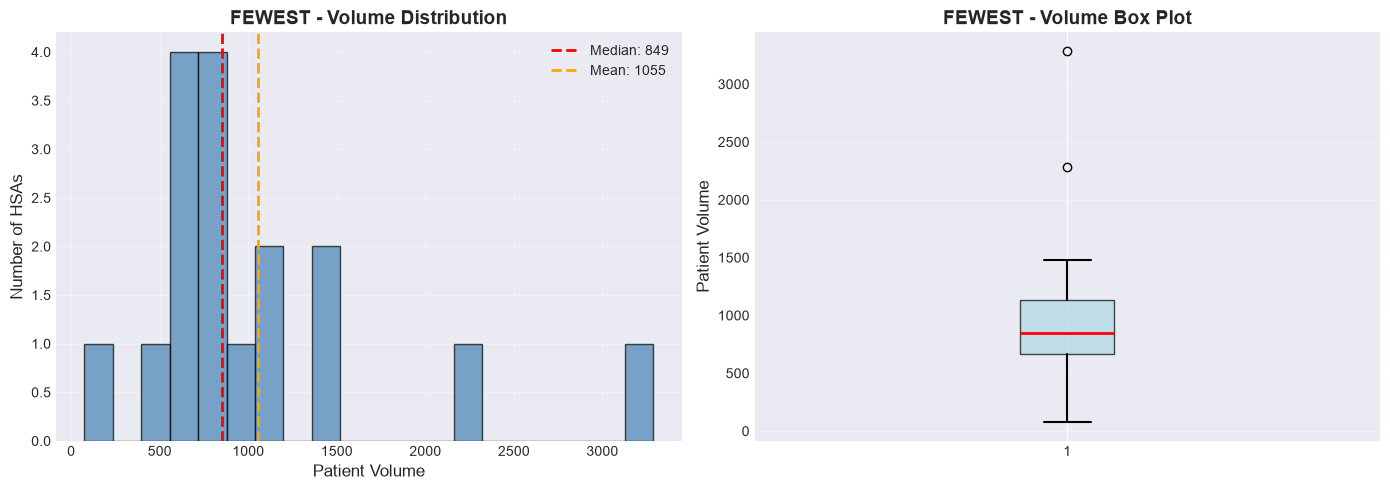


FEWEST - VOLUME QUARTILES
  Minimum:                 75
  25th Percentile:        669
  Median (50th):          849
  75th Percentile:       1134
  Maximum:               3286
  Mean:                  1055
  Std Dev:                732

FEWEST - SERVICE RADIUS ANALYSIS
  Minimum radius:     9.3 km
  Median radius:     15.4 km
  Maximum radius:    19.4 km
  Mean radius:       15.2 km
  Unique radii:        15


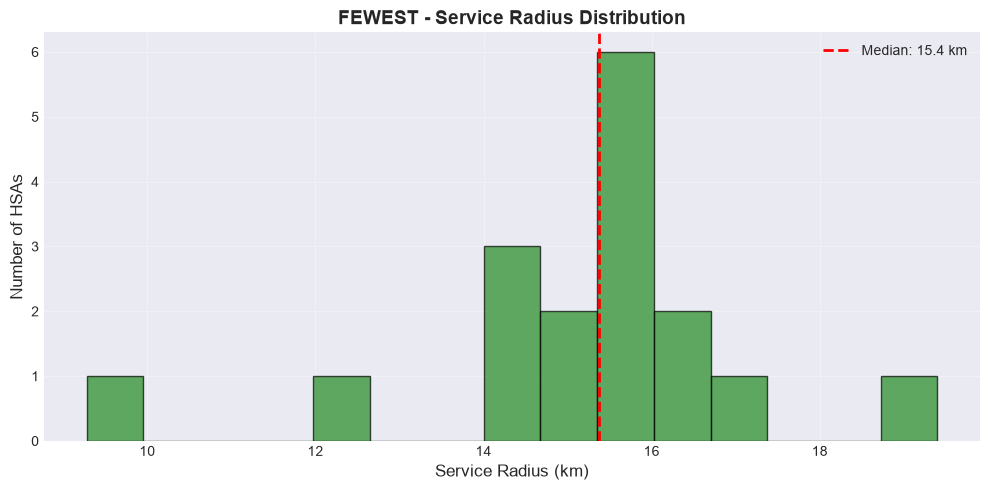

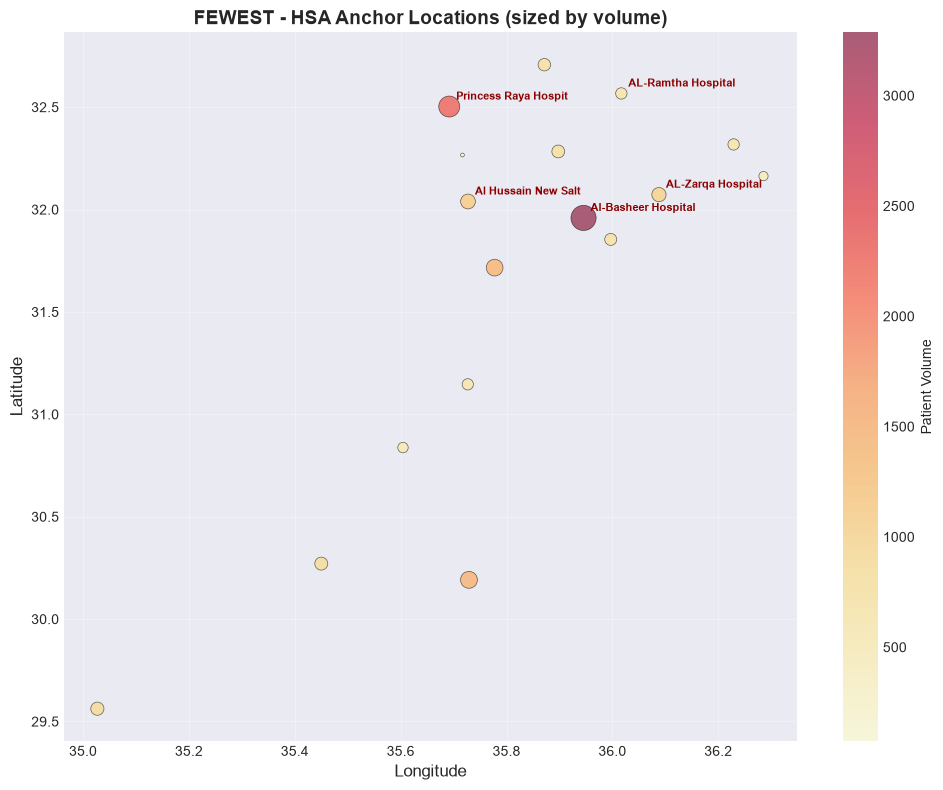


FEWEST - COMPOSITE SCORE ANALYSIS
  Score range: nan to nan
  Median score: nan
  Mean score: nan


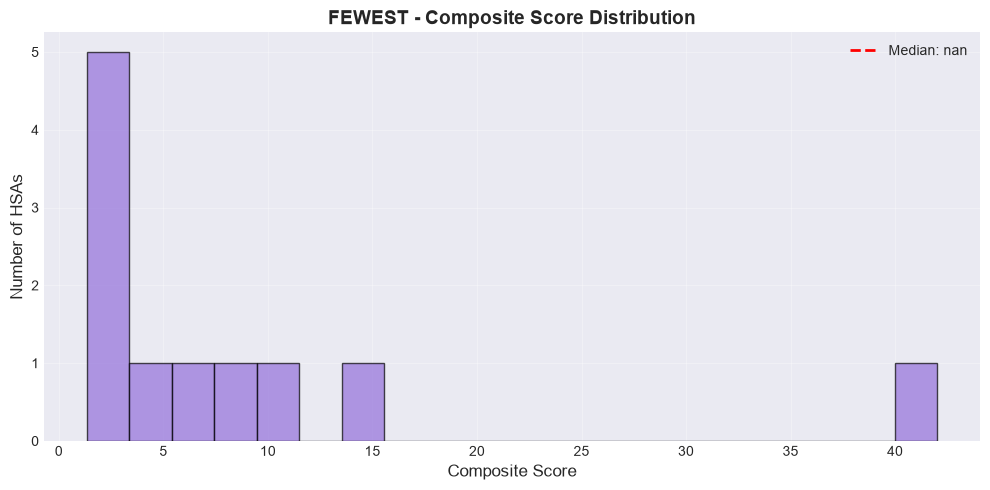


FEWEST - SELECTION ORDER ANALYSIS


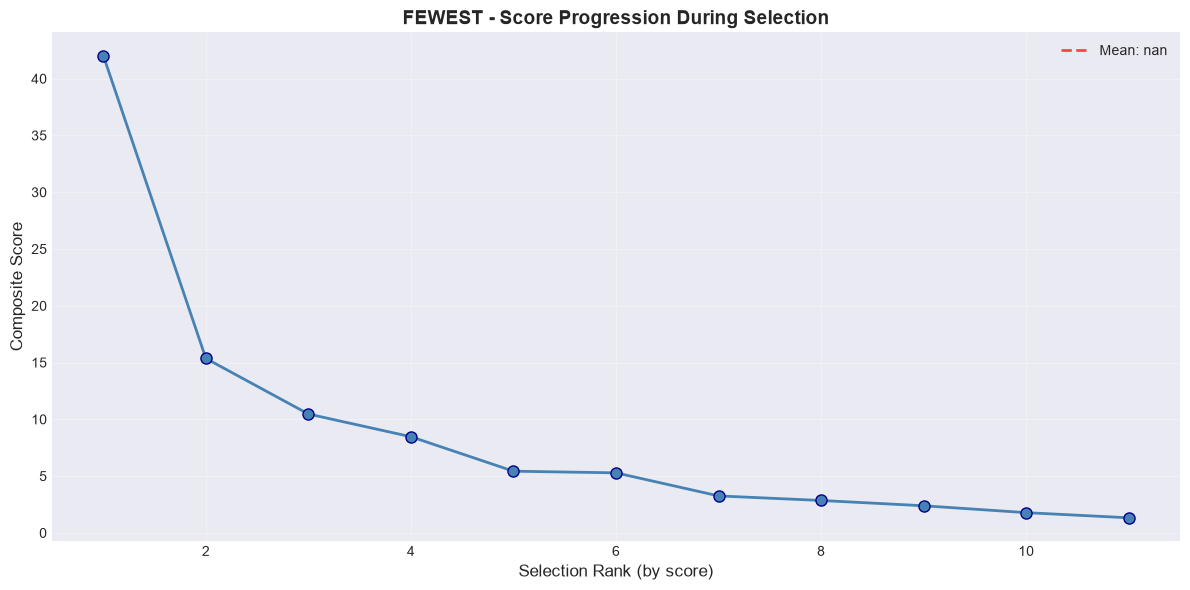

Score range: nan to nan
Score decay ratio (last/first): nan

FEWEST - VOLUME vs RADIUS CORRELATION
  Correlation coefficient: -0.083


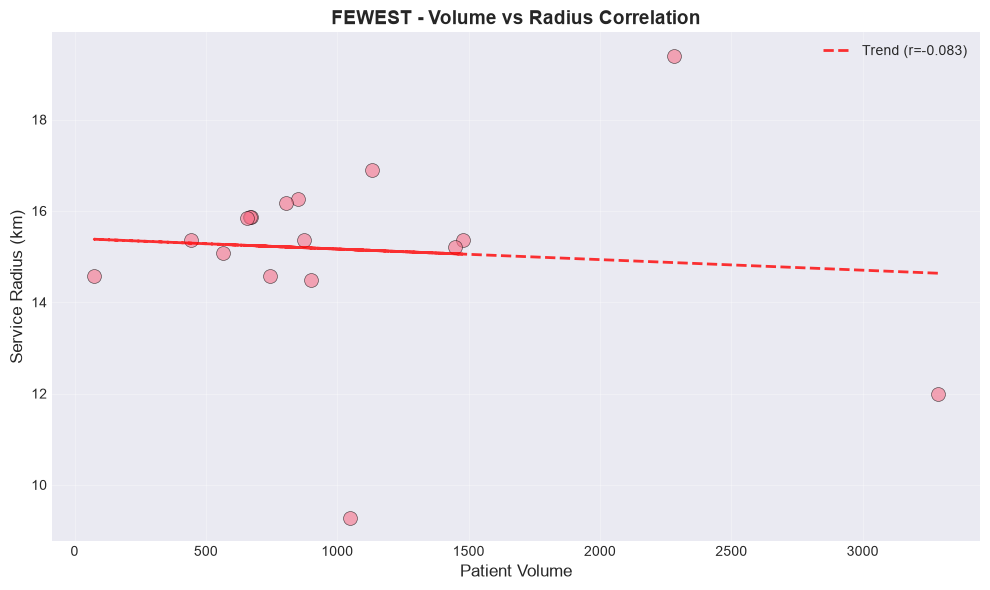


COMPLETED ANALYSIS FOR FEWEST



################################################################################
# ANALYZING MODE: FOOTPRINT
################################################################################


FOOTPRINT MODE - ALL SELECTED FACILITIES
Number of HSAs: 19
Coverage: 91.00%

Rank Facility                                       Volume       Score Radius_km
--------------------------------------------------------------------------------
1    Al-Basheer Hospital                              3286    3.44e+00      12.0
2    Princess Raya Hospital                           2282    2.02e+00      19.4
3    AL-Zarqa Hospital                                1050    1.76e+00       9.3
4    AL-Nadeem Hospital                               1450    1.45e+00      17.6
5    Al-Karak Hospital                                 656    1.35e+00      15.8
6    AL-Shuneh Hospital                               1663    1.32e+00      18.0
7    AL-Ramtha Hospital                         

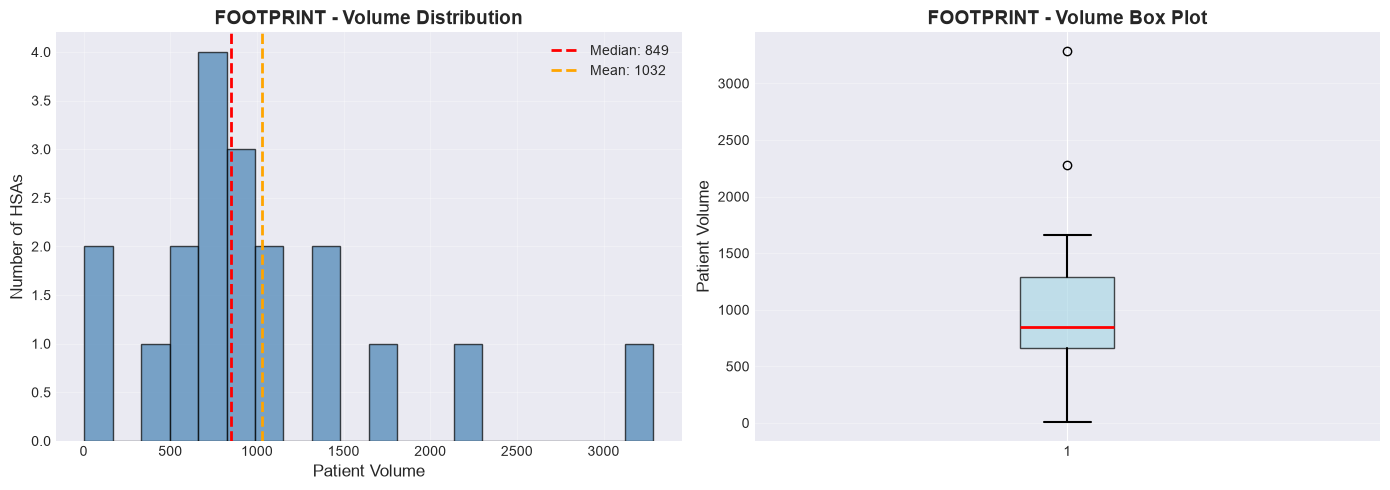


FOOTPRINT - VOLUME QUARTILES
  Minimum:                  5
  25th Percentile:        662
  Median (50th):          849
  75th Percentile:       1292
  Maximum:               3286
  Mean:                  1032
  Std Dev:                746

FOOTPRINT - SERVICE RADIUS ANALYSIS
  Minimum radius:     8.9 km
  Median radius:     15.8 km
  Maximum radius:    19.4 km
  Mean radius:       15.1 km
  Unique radii:        17


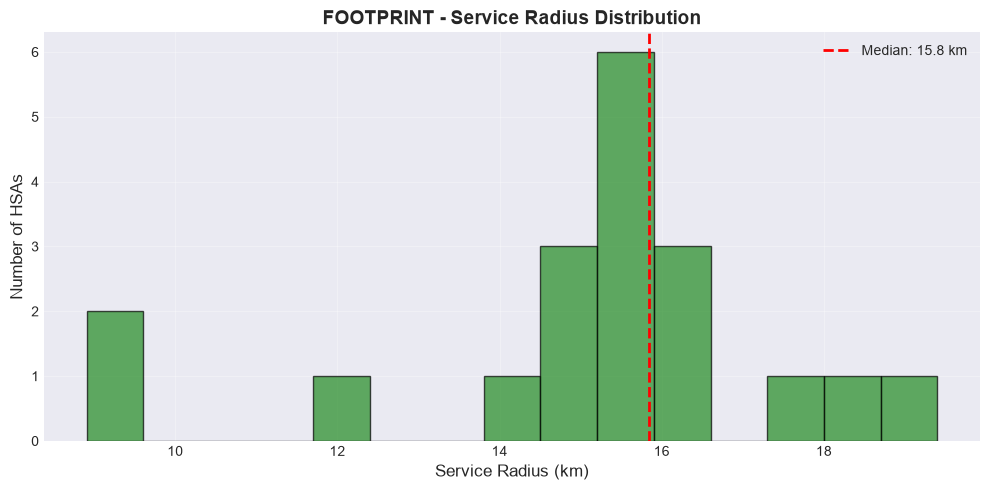

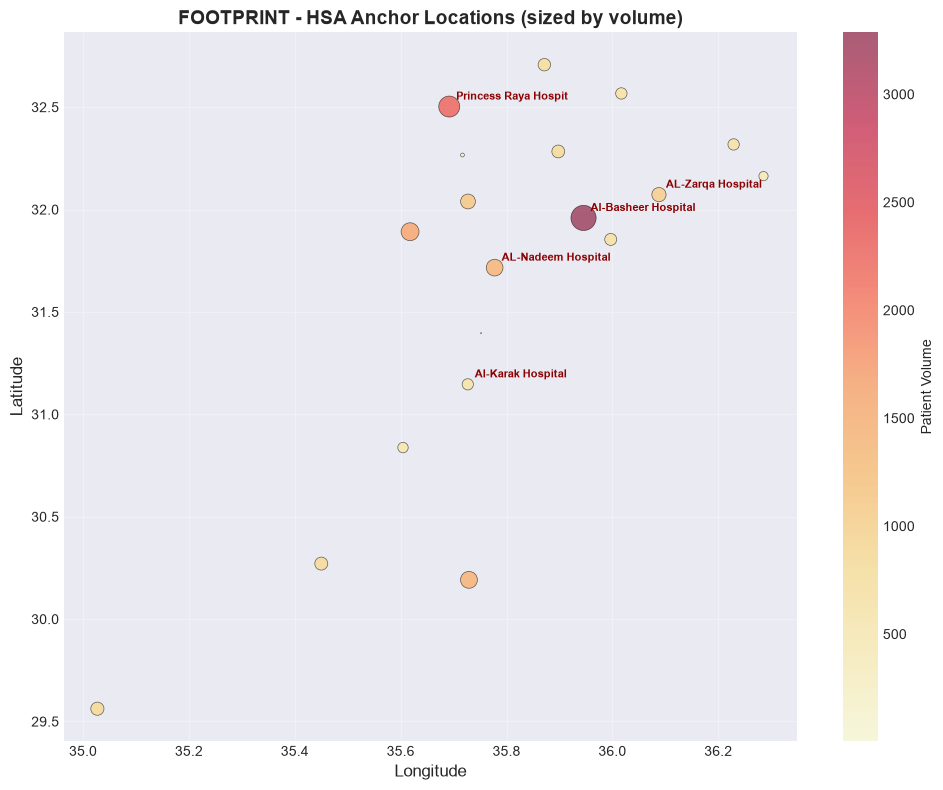


FOOTPRINT - COMPOSITE SCORE ANALYSIS
  Score range: nan to nan
  Median score: nan
  Mean score: nan


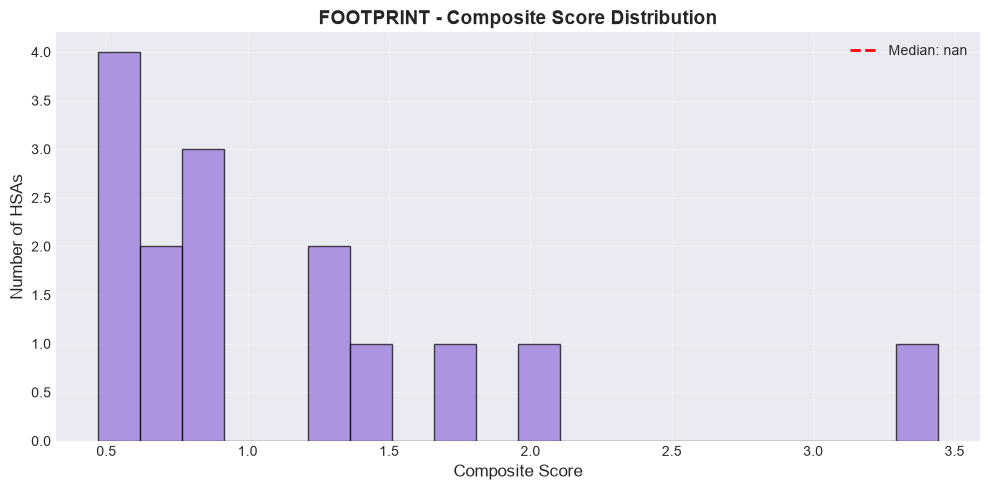


FOOTPRINT - SELECTION ORDER ANALYSIS


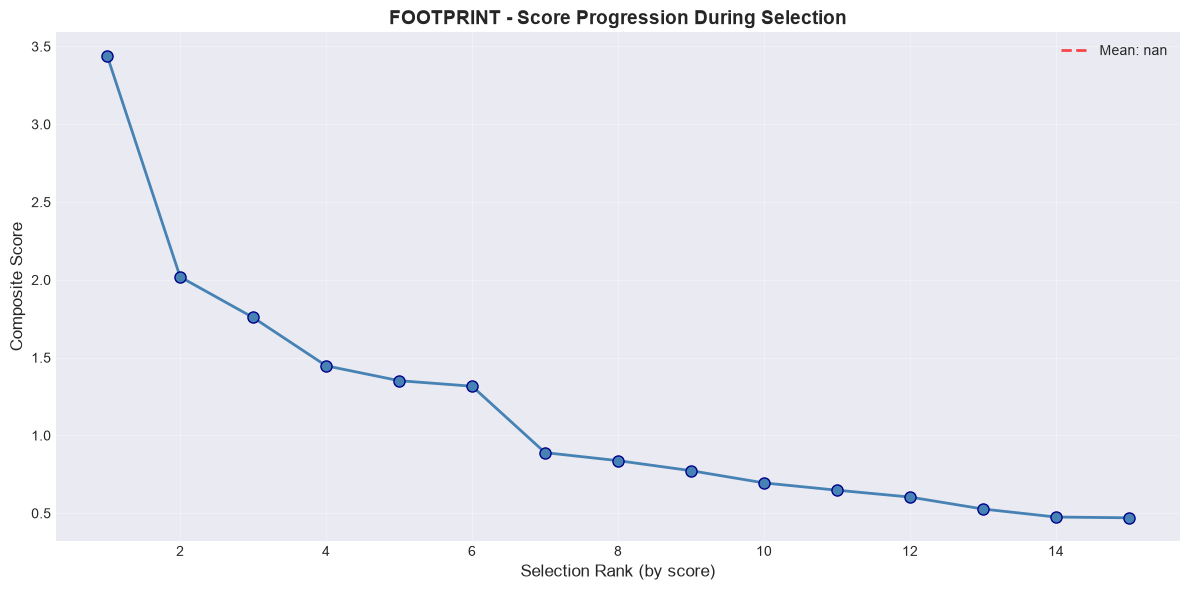

Score range: nan to nan
Score decay ratio (last/first): nan

FOOTPRINT - VOLUME vs RADIUS CORRELATION
  Correlation coefficient: 0.076


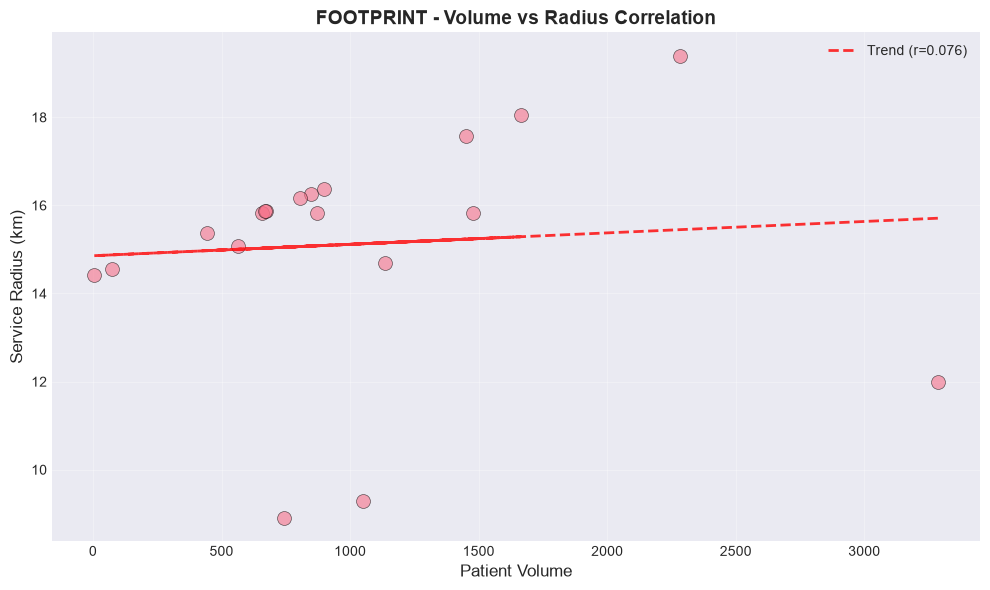


COMPLETED ANALYSIS FOR FOOTPRINT



################################################################################
# ANALYZING MODE: DISTANCE
################################################################################


DISTANCE MODE - ALL SELECTED FACILITIES
Number of HSAs: 22
Coverage: 90.50%

Rank Facility                                       Volume       Score Radius_km
--------------------------------------------------------------------------------
1    Al-Basheer Hospital                              3286    7.78e-01      12.0
2    Princess Rahma Hospital                          2880    2.56e-01      11.5
3    AL-Shuneh Hospital                               1663    6.96e-02      18.0
4    Mobes Primary Center                              155    5.74e-02       8.2
5    Princess Raya Hospital                           2282    5.64e-02      19.4
6    Mabroukeh Primary Center                          443    4.88e-02      15.4
7    Dr. Jamel Al-Totanji Hospital             

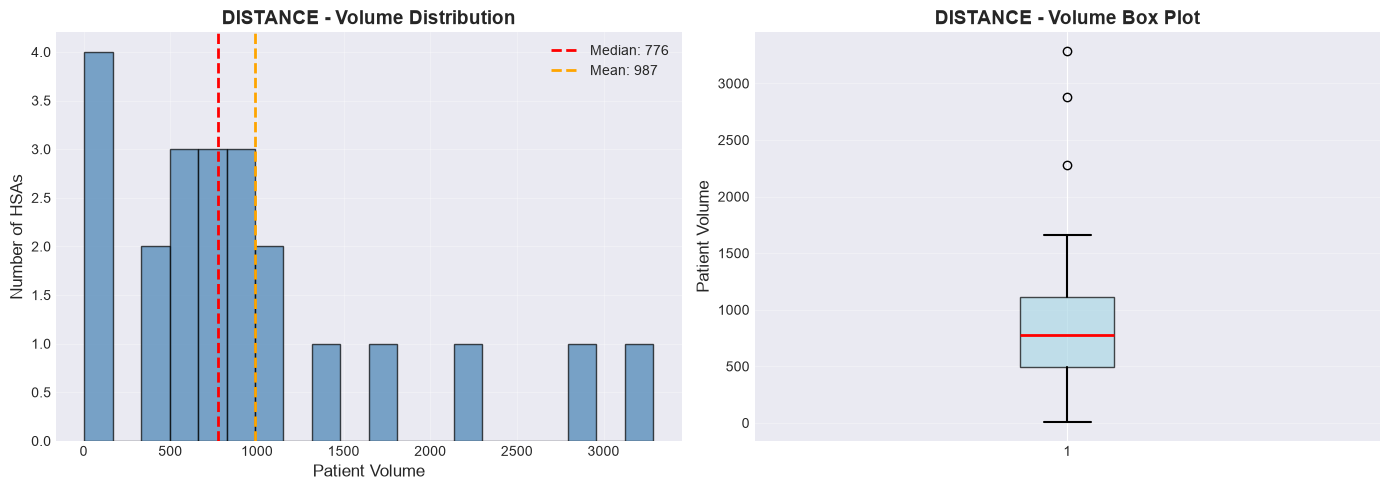


DISTANCE - VOLUME QUARTILES
  Minimum:                  5
  25th Percentile:        496
  Median (50th):          776
  75th Percentile:       1113
  Maximum:               3286
  Mean:                   987
  Std Dev:                846

DISTANCE - SERVICE RADIUS ANALYSIS
  Minimum radius:     8.1 km
  Median radius:     14.6 km
  Maximum radius:    19.4 km
  Mean radius:       13.5 km
  Unique radii:        22


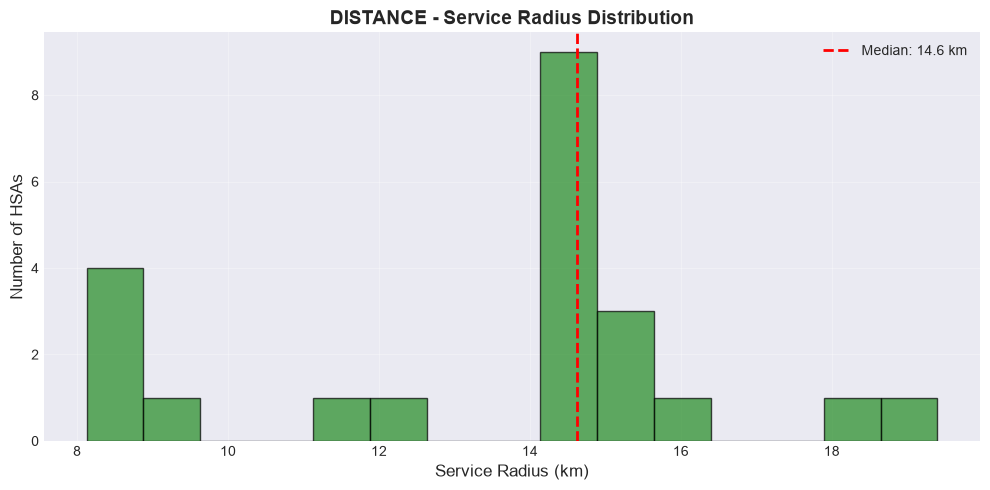

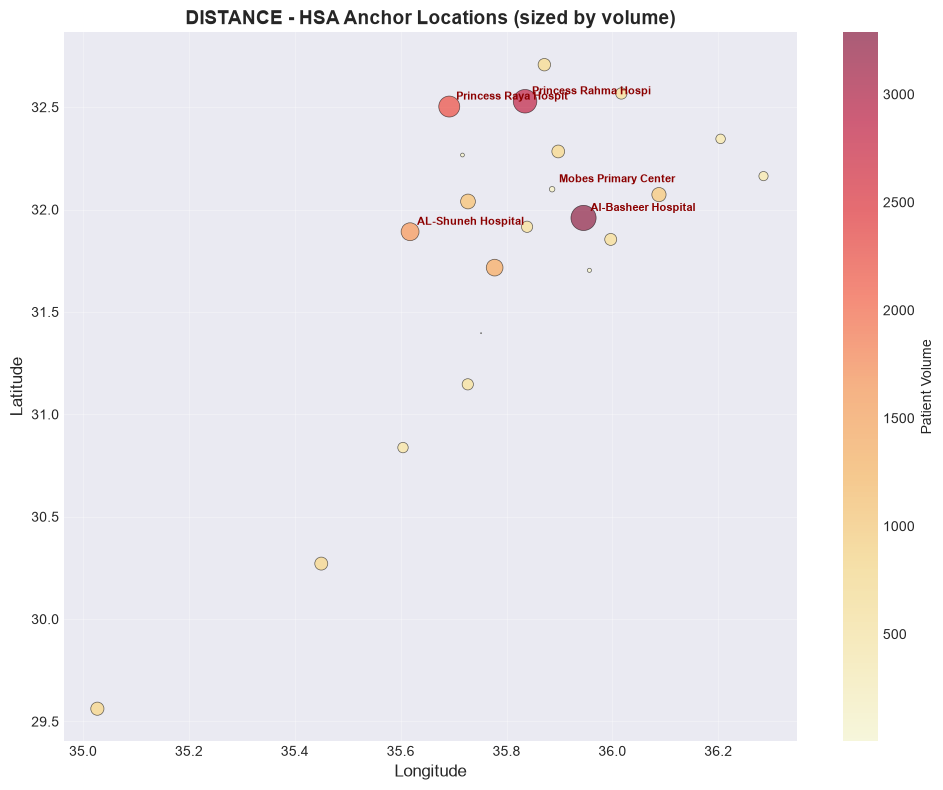


DISTANCE - COMPOSITE SCORE ANALYSIS
  Score range: nan to nan
  Median score: nan
  Mean score: nan


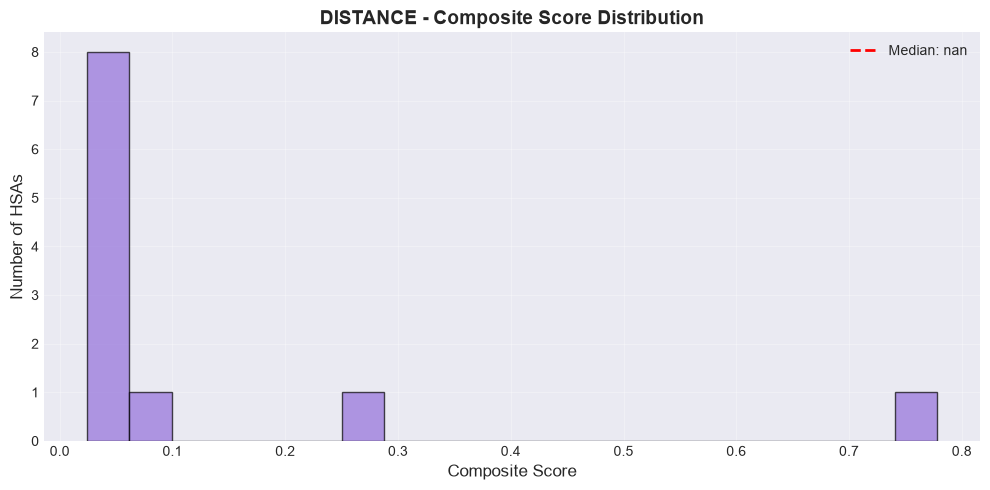


DISTANCE - SELECTION ORDER ANALYSIS


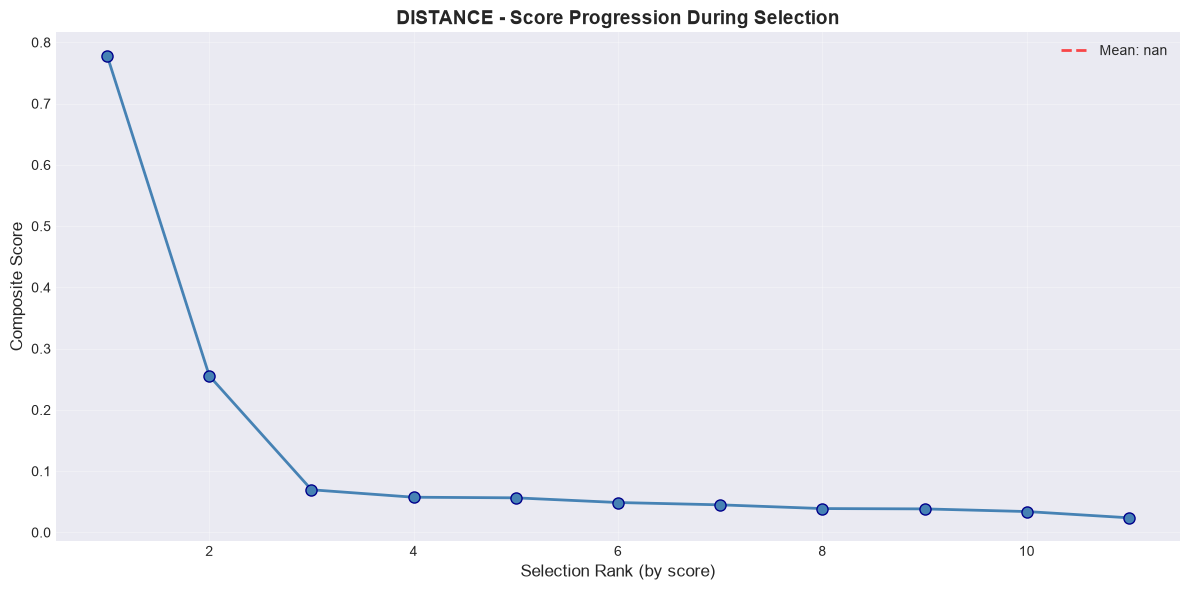

Score range: nan to nan
Score decay ratio (last/first): nan

DISTANCE - VOLUME vs RADIUS CORRELATION
  Correlation coefficient: 0.052


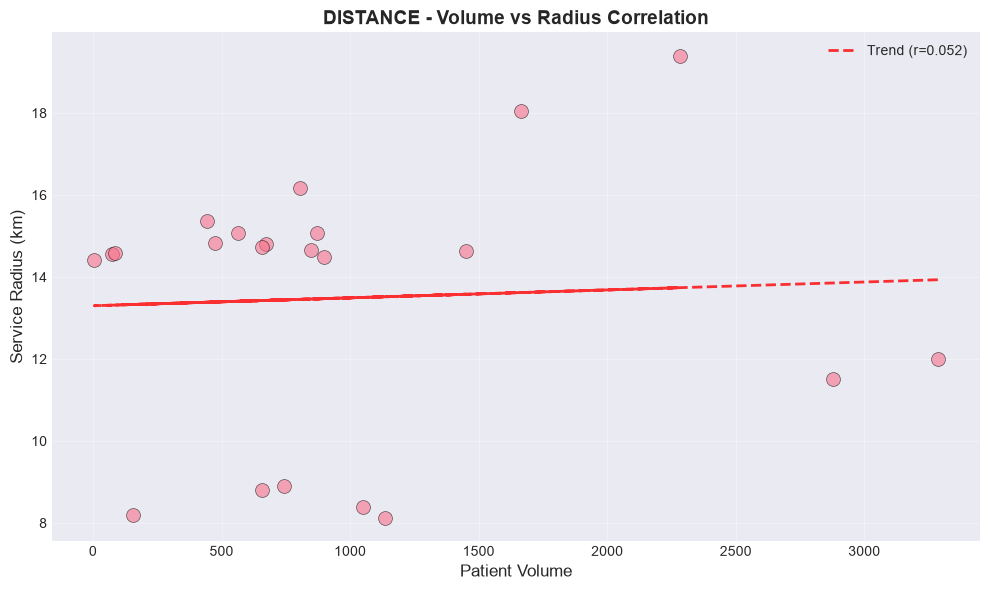


COMPLETED ANALYSIS FOR DISTANCE



################################################################################
# ANALYZING MODE: GOVERNORATE_TAU_COVERAGE
################################################################################


GOVERNORATE_TAU_COVERAGE MODE - ALL SELECTED FACILITIES
Number of HSAs: 45
Coverage: 89.17%

Rank Facility                                       Volume       Score Radius_km
--------------------------------------------------------------------------------
1    Al-Basheer Hospital                              3286    3.17e+07      13.0
2    AL-Zarqa Hospital                                1050    7.19e+06      12.7
3    Princess Raya Hospital                           2282    6.52e+06      12.9
4    Princess Rahma Hospital                          2880    5.43e+06      13.0
5    Al Hussain New Salt Hospital                     1134    4.67e+06      12.8
6    Arish Primary Center                              372    3.28e+06      11.1
7    AL-Ramtha H

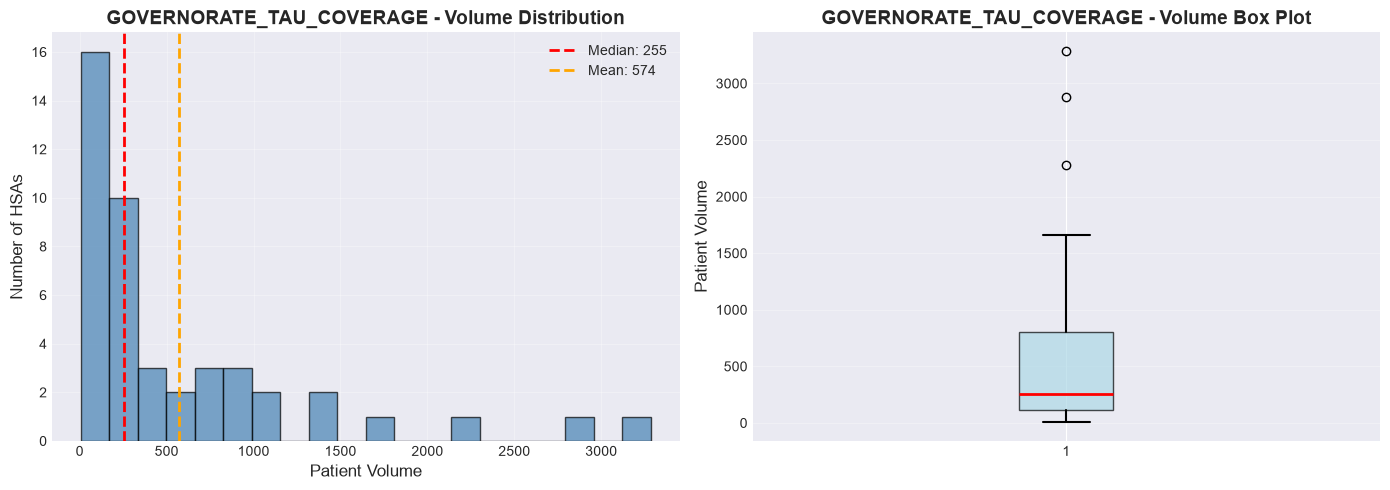


GOVERNORATE_TAU_COVERAGE - VOLUME QUARTILES
  Minimum:                  5
  25th Percentile:        112
  Median (50th):          255
  75th Percentile:        806
  Maximum:               3286
  Mean:                   574
  Std Dev:                740

GOVERNORATE_TAU_COVERAGE - SERVICE RADIUS ANALYSIS
  Minimum radius:     7.2 km
  Median radius:     10.4 km
  Maximum radius:    13.0 km
  Mean radius:       10.4 km
  Unique radii:        44


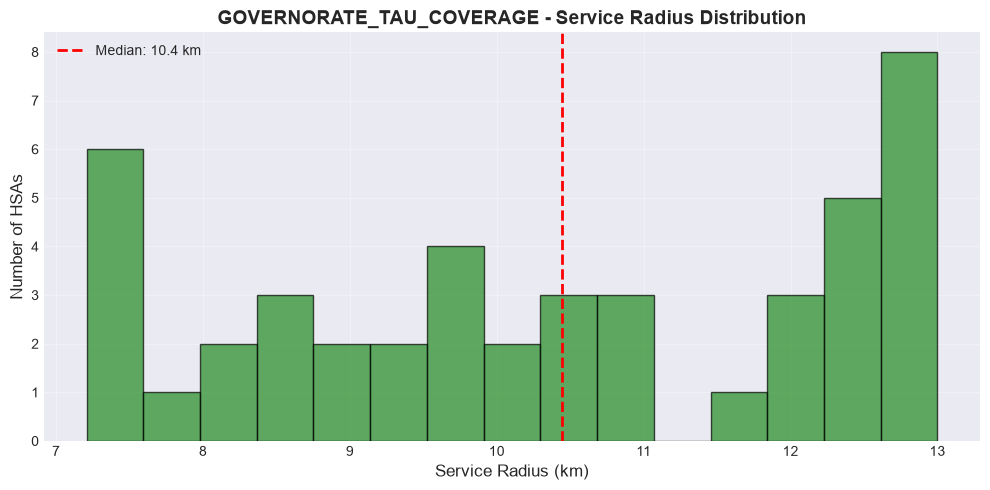

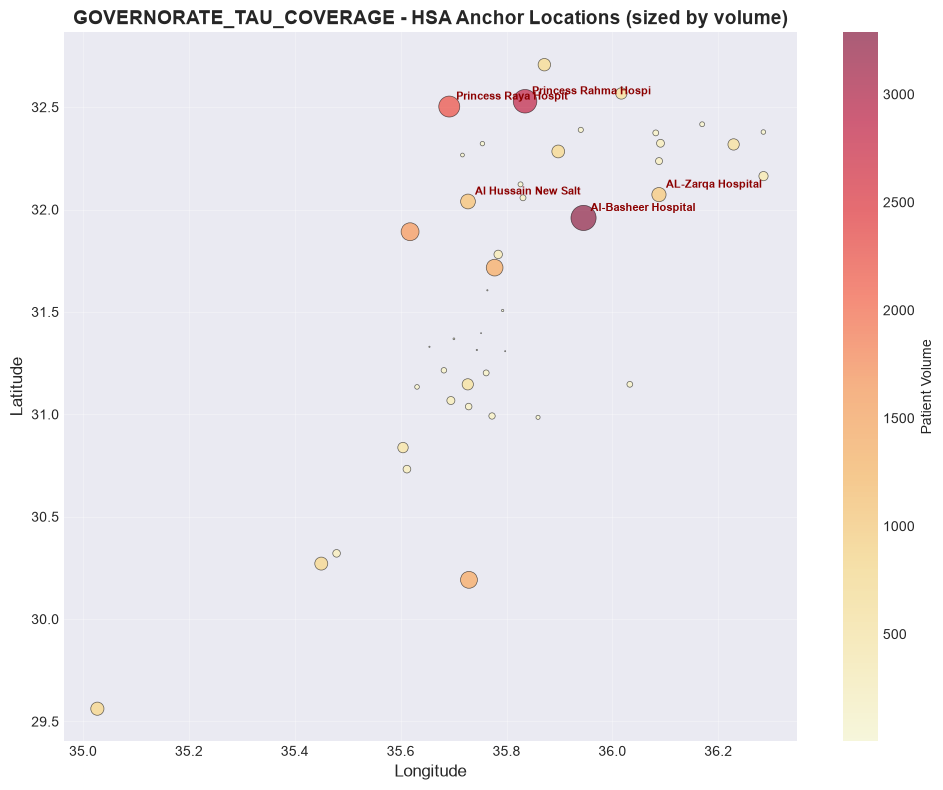


GOVERNORATE_TAU_COVERAGE - COMPOSITE SCORE ANALYSIS
  Score range: 1.03e+04 to 3.17e+07
  Median score: 4.30e+05
  Mean score: 1.86e+06


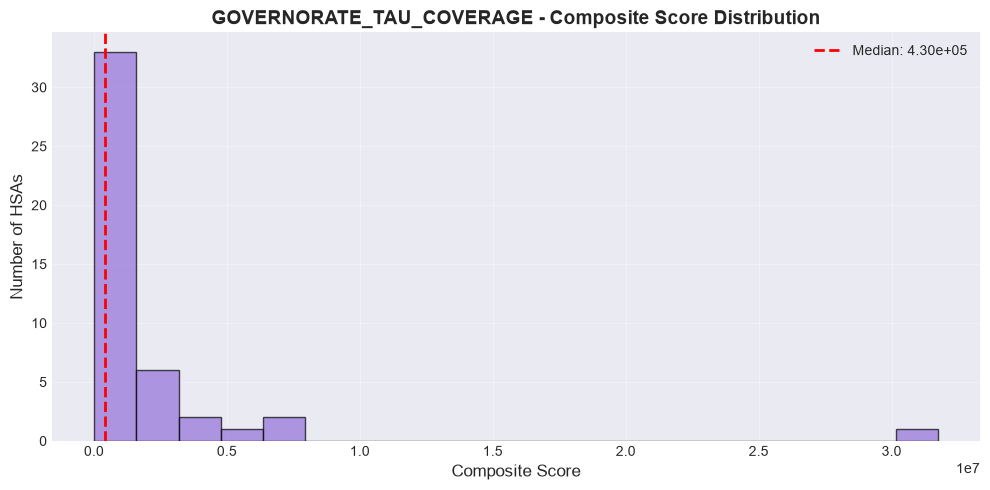


GOVERNORATE_TAU_COVERAGE - SELECTION ORDER ANALYSIS


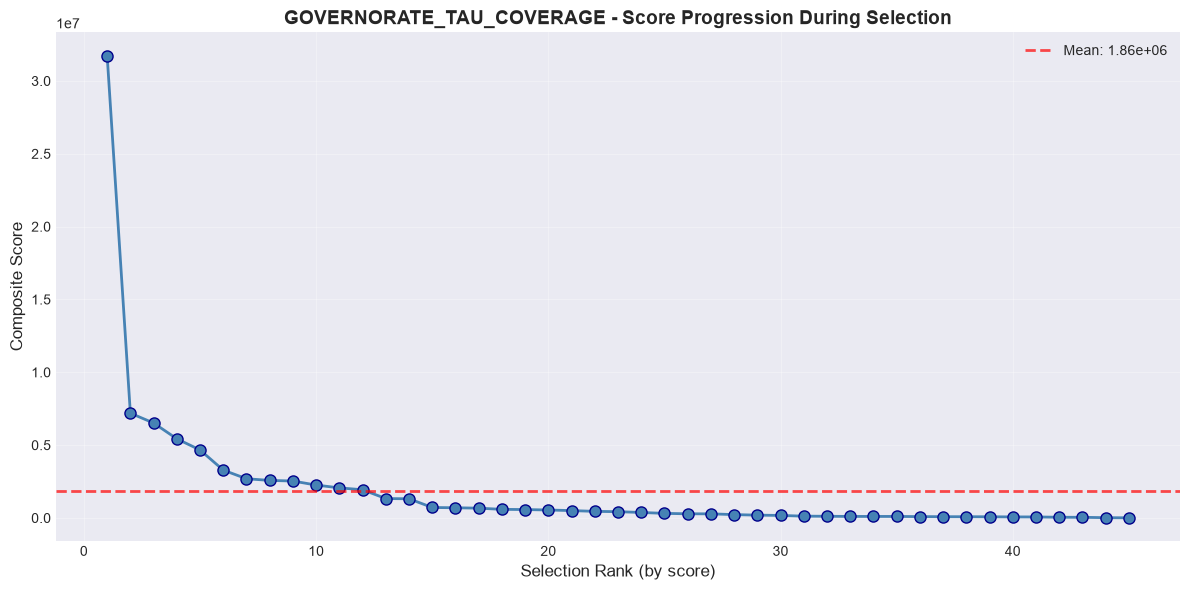

Score range: 1.03e+04 to 3.17e+07
Score decay ratio (last/first): 0.000

GOVERNORATE_TAU_COVERAGE - VOLUME vs RADIUS CORRELATION
  Correlation coefficient: 0.754


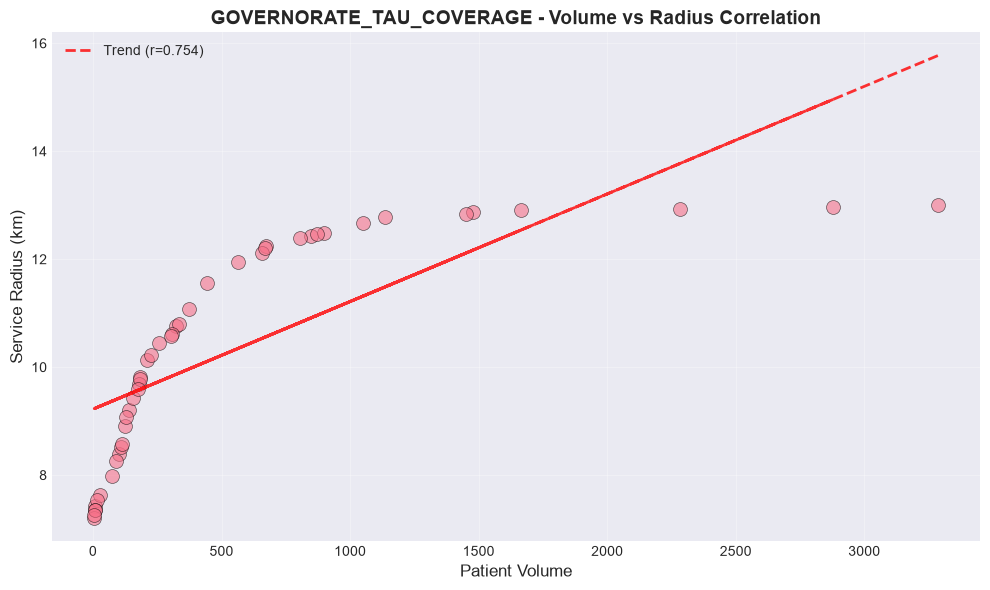


COMPLETED ANALYSIS FOR GOVERNORATE_TAU_COVERAGE



################################################################################
# ANALYZING MODE: GOVERNORATE_FEWEST
################################################################################


GOVERNORATE_FEWEST MODE - ALL SELECTED FACILITIES
Number of HSAs: 18
Coverage: 90.38%

Rank Facility                                       Volume       Score Radius_km
--------------------------------------------------------------------------------
1    Al Hussain New Salt Hospital                     1134    6.95e+00      16.9
2    Princess Raya Hospital                           2282    4.22e+00      19.4
3    AL-Ramtha Hospital                                673    3.33e+00      15.9
4    Mabroukeh Primary Center                          443    2.39e+00      15.4
5    Al-Yarmouk Hospital                               806    1.22e+00      16.2
6    Al-Basheer Hospital                              3286    0.00e+00      12.0
7    Tafilah

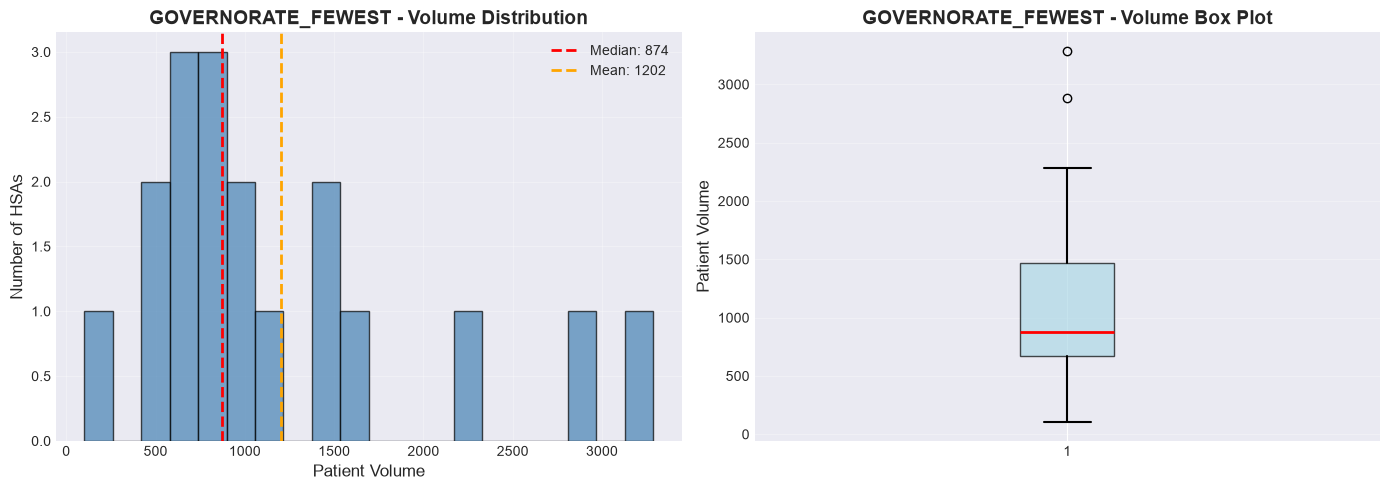


GOVERNORATE_FEWEST - VOLUME QUARTILES
  Minimum:                102
  25th Percentile:        670
  Median (50th):          874
  75th Percentile:       1472
  Maximum:               3286
  Mean:                  1202
  Std Dev:                828

GOVERNORATE_FEWEST - SERVICE RADIUS ANALYSIS
  Minimum radius:     9.3 km
  Median radius:     15.9 km
  Maximum radius:    19.4 km
  Mean radius:       15.5 km
  Unique radii:        18


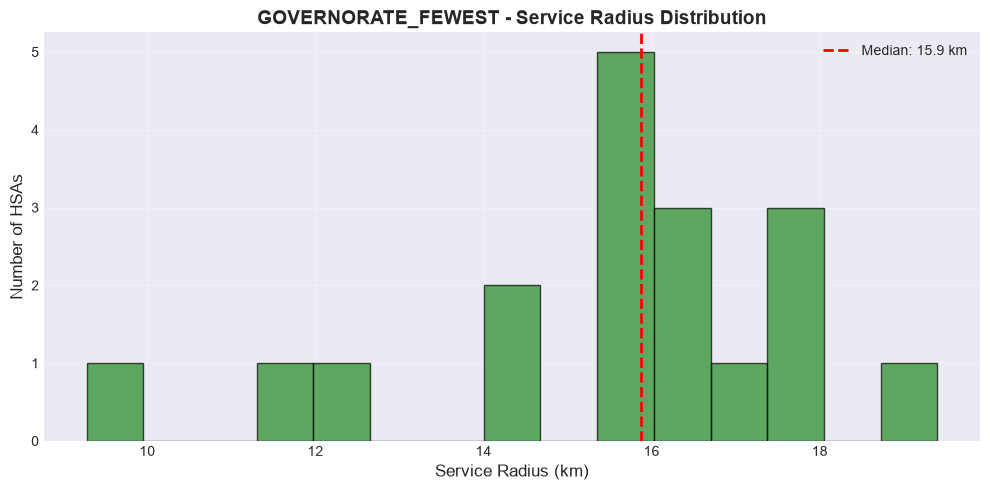

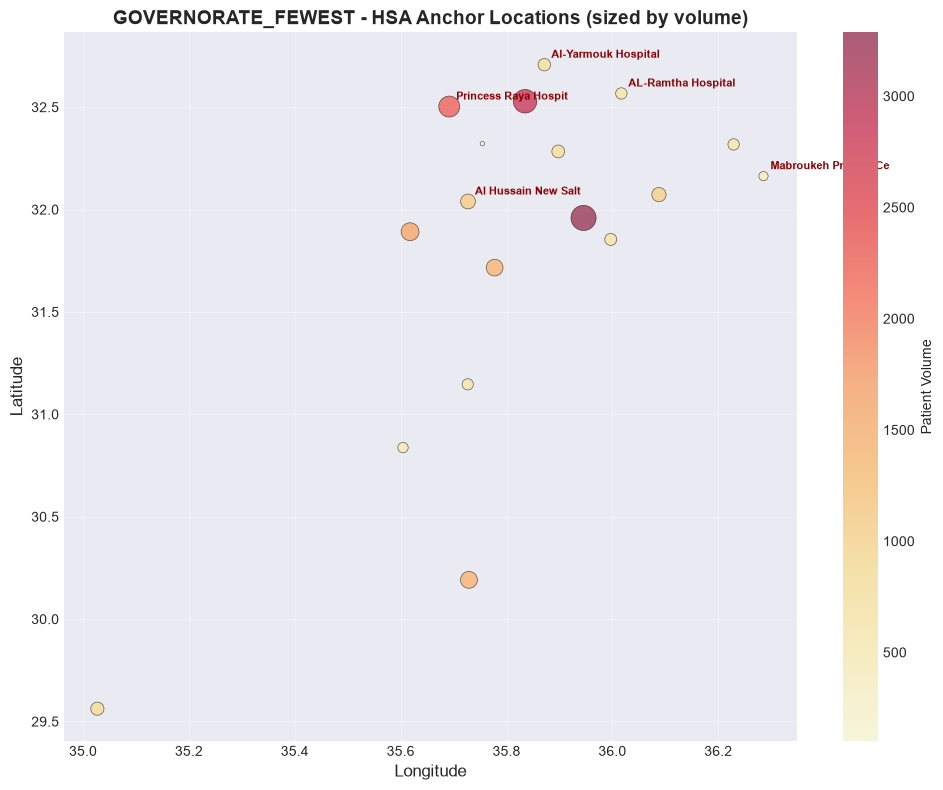


GOVERNORATE_FEWEST - COMPOSITE SCORE ANALYSIS
  Score range: nan to nan
  Median score: nan
  Mean score: nan


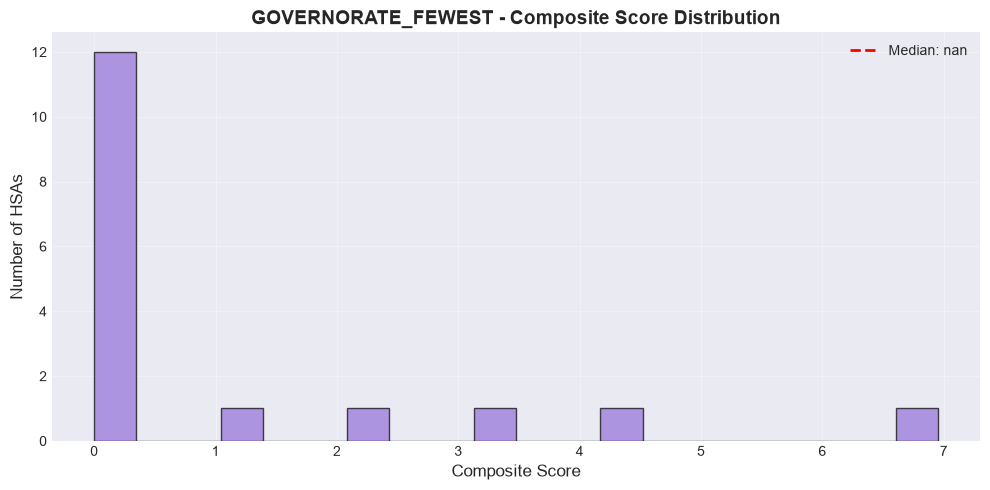


GOVERNORATE_FEWEST - SELECTION ORDER ANALYSIS


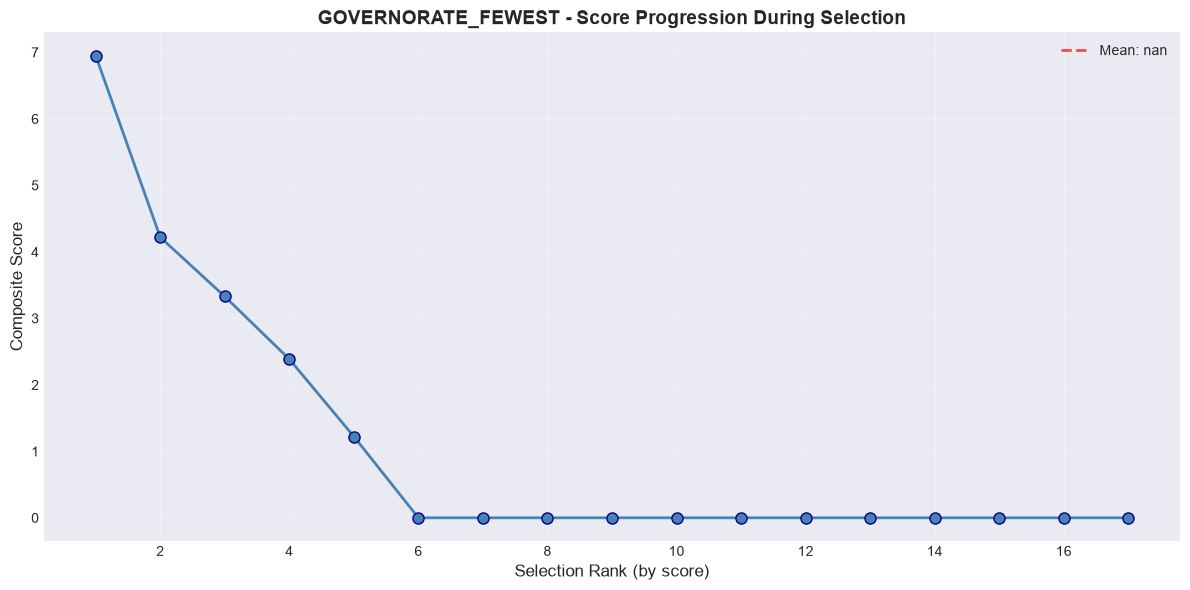

Score range: nan to nan
Score decay ratio (last/first): nan

GOVERNORATE_FEWEST - VOLUME vs RADIUS CORRELATION
  Correlation coefficient: -0.187


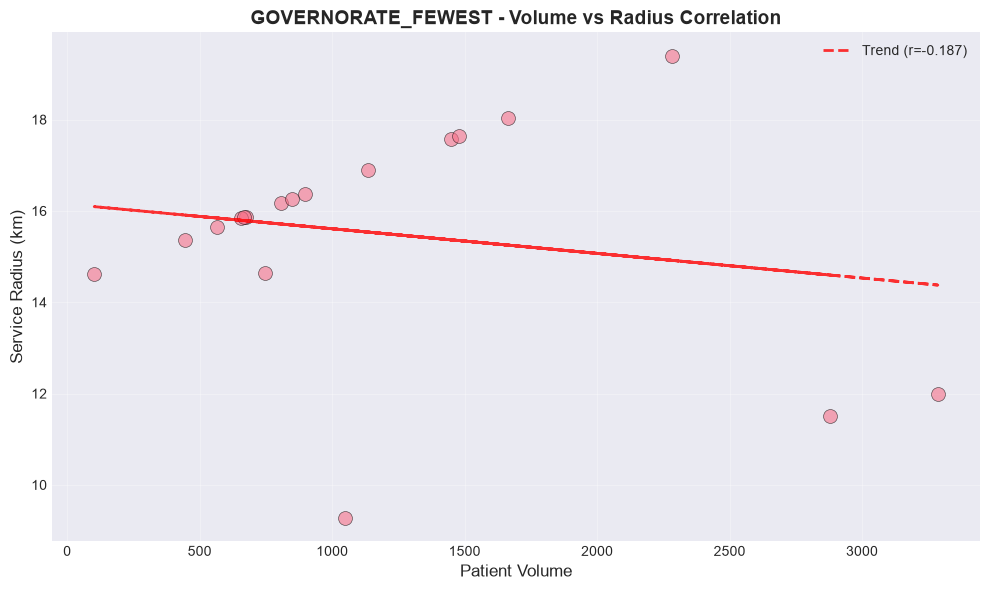


COMPLETED ANALYSIS FOR GOVERNORATE_FEWEST


################################################################################
# ALL MODES ANALYZED
################################################################################


In [5]:
# ============================================================================
# SECTIONS 3-8: ANALYZE ALL OPTIMIZATION MODES
# ============================================================================

from hsa_objective_analysis import analyze_all_modes

# Analyze all modes with complete suite of visualizations and statistics
analyze_all_modes(all_results)

In [6]:
# ============================================================================
# HELPER: Normalize composite scores for cross-mode comparison
# ============================================================================

import numpy as np
import pandas as pd

def _normalize_scores_per_mode(all_results):
    summary_rows = []
    for mode, data in all_results.items():
        df = data.get('facilities')
        if df is None or 'composite_score' not in df.columns:
            continue
        scores = df['composite_score'].astype(float)
        min_s = scores.min()
        max_s = scores.max()
        if max_s > min_s:
            norm = (scores - min_s) / (max_s - min_s)
        else:
            norm = scores * 0.0
        std = scores.std(ddof=0)
        if std > 0:
            z = (scores - scores.mean()) / std
        else:
            z = scores * 0.0
        df = df.copy()
        df['composite_score_norm'] = norm
        df['composite_score_z'] = z
        data['facilities'] = df
        summary_rows.append({
            'mode': mode,
            'min': min_s,
            'median': scores.median(),
            'mean': scores.mean(),
            'max': max_s,
            'mean_norm': norm.mean(),
            'median_norm': float(np.median(norm)),
        })
    if not summary_rows:
        return pd.DataFrame()
    return pd.DataFrame(summary_rows).sort_values('mode')

score_summary = _normalize_scores_per_mode(all_results)
if not score_summary.empty:
    display(score_summary)
    print("Normalized scores added per mode: composite_score_norm (0-1) and composite_score_z (z-score).")
else:
    print("No composite_score column found in all_results.")


,mode,min,median,mean,max,mean_norm,median_norm
2,distance,0.023838,0.048786,1.314863e-01,7.783983e-01,0.142663,NaN
0,fewest,1.326396,5.284767,8.966012e+00,4.202700e+01,0.187703,NaN
1,footprint,0.470696,0.838030,1.150446e+00,3.441440e+00,0.228815,NaN
4,governorate_fewest,0.000000,0.000000,1.065114e+00,6.950814e+00,0.153236,NaN
3,governorate_tau_coverage,10299.062807,430276.382702,1.860673e+06,3.173775e+07,0.058321,0.013237


Normalized scores added per mode: composite_score_norm (0-1) and composite_score_z (z-score).


In [7]:
# ============================================================================
# CROSS-MODE COMPARISON: Facility Counts and HSA Volumes
# ============================================================================

from geopandas import sjoin
import rasterio
from rasterio.mask import mask as raster_mask
import pandas as pd


# Load all facilities once from climate CSV + diagnosis counts
# Facility climate is a shared input produced once by GEE Step A, before any
# delineation exists. Look in the run directory first, then out/, then data/ --
# the synthetic networks ship it there so the pipeline runs without an Earth
# Engine account. These features depend only on facility location.
climate_csv = OUT_DIR / f'{NETWORK}_Facilities_Climate_Features_with_clusters.csv'
if not climate_csv.exists():
    for _alt in (Path('out') / climate_csv.name, DATA_DIR / climate_csv.name):  # noqa: hardcode - out/ holds the canonical facility-climate master
        if _alt.exists():
            print(f"  Facility climate not in {OUT_DIR}; using {_alt}")
            climate_csv = _alt
            break
# Diagnosis counts path resolution: mode-aware when available, safe fallback when not.
mode_suffix = f"_{HSA_MODE}" if 'HSA_MODE' in globals() and HSA_MODE else ""
diag_candidates = []
if mode_suffix:
    diag_candidates.append(OUT_DIR / f'{NETWORK}{mode_suffix}_diagnosis_counts_pivot.csv')
diag_candidates.extend([
    OUT_DIR / f'{NETWORK}_diagnosis_counts_pivot.csv',
    OUT_DIR / f'{NETWORK}_footprint_diagnosis_counts_pivot.csv',
])

diagnosis_csv = next((c for c in diag_candidates if c.exists()), diag_candidates[0])

climate_df = pd.read_csv(climate_csv)
diagnosis_df = pd.read_csv(diagnosis_csv)

# Rename FacilityName to HealthFacility
if 'FacilityName' in climate_df.columns:
    climate_df['HealthFacility'] = climate_df['FacilityName']

# NORMALIZE WHITESPACE: Collapse multiple spaces to single space
climate_df['HealthFacility'] = climate_df['HealthFacility'].str.replace(r'\s+', ' ', regex=True).str.strip()
diagnosis_df['healthfacility'] = diagnosis_df['healthfacility'].str.replace(r'\s+', ' ', regex=True).str.strip()

# Merge
merged_df = climate_df.merge(
    diagnosis_df[['healthfacility', 'total_diagnoses']],
    left_on='HealthFacility',
    right_on='healthfacility',
    how='left'
)
merged_df['Total'] = merged_df['total_diagnoses'].fillna(0)

all_facilities = gpd.GeoDataFrame(
    merged_df,
    geometry=gpd.points_from_xy(merged_df['lon'], merged_df['lat']),
    crs='EPSG:4326'
).to_crs('EPSG:32637')


def _mode_hsa_polygons(mode):
    """Load the saved HSA polygons for the current ALGO_VERSION; rebuild from anchors if missing."""
    hsas_file = OUT_DIR / f'{NETWORK}_{mode}_hsas_{ALGO_VERSION}.geojson'
    if hsas_file.exists():
        return gpd.read_file(hsas_file).to_crs('EPSG:32637')

    final_hsas_raw = all_results[mode]['facilities'].copy()
    hsas_polygons = hsa_optimization.create_hsa_polygons(final_hsas_raw)
    final_hsas_raw['geometry'] = hsas_polygons.geometry.values
    if final_hsas_raw.crs is None:
        return final_hsas_raw.set_crs('EPSG:32637')
    return final_hsas_raw.to_crs('EPSG:32637')


# Compare all modes
comparison_results = []

for mode in ['fewest', 'footprint', 'distance', 'governorate_tau_coverage', 'governorate_fewest']:
    if mode not in all_results:
        continue

    final_hsas_utm = _mode_hsa_polygons(mode)
    N_ANCHORS = len(final_hsas_utm)

    print(f"\n{'='*80}")
    print(f"{mode.upper()} - DETAILED HSA ANALYSIS ({N_ANCHORS} HSAs)")
    print('='*80)

    details = []

    for idx, row in final_hsas_utm.iterrows():
        fac_name = row.get('HealthFacility', row.get('FacilityName', str(idx)))
        hsa_geom_utm = row.geometry
        if hsa_geom_utm is None or getattr(hsa_geom_utm, 'is_empty', False):
            print(f"  WARNING: Empty HSA geometry for {fac_name}")
            continue

        anchor_volume = pd.to_numeric(row.get('Total', 0), errors='coerce')
        radius_km = row.get('service_radius_km', row.get('initial_radius_km', 15.0))

        hsa_temp = gpd.GeoDataFrame([{'geometry': hsa_geom_utm}], crs=final_hsas_utm.crs)
        facilities_in_hsa = sjoin(all_facilities, hsa_temp, how='inner', predicate='intersects')

        total_hsa_volume = 0
        for fac_idx, fac_row in facilities_in_hsa.iterrows():
            fac_vol = pd.to_numeric(fac_row['Total'], errors='coerce')
            if not pd.isna(fac_vol):
                total_hsa_volume += fac_vol

        hsa_geom_latlon = gpd.GeoDataFrame(
            [{'geometry': hsa_geom_utm}],
            crs=final_hsas_utm.crs
        ).to_crs('EPSG:4326').geometry.iloc[0]

        try:
            with rasterio.open(config['pop_path']) as src:
                out_image, out_transform = raster_mask(src, [hsa_geom_latlon], crop=True, nodata=0)
                total_pop = float(out_image.sum())
        except Exception:
            total_pop = 0

        details.append({
            'Mode': mode.upper(),
            'HSA_Anchor': row.get('FacilityName', fac_name),
            'Anchor_Patient_Volume': anchor_volume,
            'Num_Facilities_in_HSA': len(facilities_in_hsa),
            'Total_HSA_Volume': total_hsa_volume,
            'HSA_Population': total_pop,
            'Service_Radius_km': radius_km,
            'Satellite_Bubbles': row.get('satellite_bubble_count', 0),
            'Bubble_Area_Added_km2': row.get('satellite_bubble_area_added_km2', 0.0),
            'Composite_Score': row.get('composite_score', 0)
        })

    detail_df = pd.DataFrame(details)

    display_cols = ['HSA_Anchor', 'Anchor_Patient_Volume', 'Num_Facilities_in_HSA',
                    'Total_HSA_Volume', 'HSA_Population', 'Service_Radius_km',
                    'Satellite_Bubbles', 'Bubble_Area_Added_km2', 'Composite_Score']

    print(detail_df[display_cols].to_string(index=False))

    print(f"\nSummary Statistics for {mode.upper()}:")
    print(f"  Total HSAs: {len(detail_df)}")
    print(f"  Avg facilities per HSA: {detail_df['Num_Facilities_in_HSA'].mean():.1f}")
    print(f"  Total facilities covered: {detail_df['Num_Facilities_in_HSA'].sum()}")
    print(f"  Avg HSA volume: {detail_df['Total_HSA_Volume'].mean():,.0f}")
    print(f"  Total HSA volume: {detail_df['Total_HSA_Volume'].sum():,.0f}")
    print(f"  Satellite bubbles: {pd.to_numeric(detail_df['Satellite_Bubbles'], errors='coerce').fillna(0).sum():.0f}")

    comparison_results.append({
        'Mode': mode.upper(),
        'Num_HSAs': N_ANCHORS,
        'Avg_Facilities_per_HSA': detail_df['Num_Facilities_in_HSA'].mean(),
        'Total_Facilities_Covered': detail_df['Num_Facilities_in_HSA'].sum(),
        'Avg_HSA_Volume': detail_df['Total_HSA_Volume'].mean(),
        'Total_HSA_Volume': detail_df['Total_HSA_Volume'].sum(),
        'Satellite_Bubbles': pd.to_numeric(detail_df['Satellite_Bubbles'], errors='coerce').fillna(0).sum(),
    })

print(f"\n\n{'='*80}")
print("CROSS-MODE COMPARISON SUMMARY")
print('='*80)
comparison_df = pd.DataFrame(comparison_results)
print(comparison_df.to_string(index=False))


  Facility climate not in out; using data/SYNMODINF_Facilities_Climate_Features_with_clusters.csv

FEWEST - DETAILED HSA ANALYSIS (17 HSAs)
                                  HSA_Anchor  Anchor_Patient_Volume  Num_Facilities_in_HSA  Total_HSA_Volume  HSA_Population  Service_Radius_km  Satellite_Bubbles  Bubble_Area_Added_km2  Composite_Score
                         Al-Basheer Hospital                   3286                     38             22620    3.430042e+06          12.000000                  0                    0.0        42.026998
                      Princess Raya Hospital                   2282                     11              8875    8.583258e+05          19.400122                  0                    0.0        15.357354
                Al Hussain New Salt Hospital                   1134                     14              5784    9.068718e+05          16.884723                  0                    0.0         8.464826
                           AL-Zarqa Hospital    

## Generate HSA Maps

Create HSA boundary polygons and professional maps for all optimization results.

In [8]:
# Load Jordan country boundary for clipping
country_file = DATA_DIR / 'jordan_admin0.gpkg'  # Adjust filename if needed
if not country_file.exists():
    country_file = DATA_DIR / 'jordan_boundary.gpkg'
if not country_file.exists():
    country_file = DATA_DIR / 'jordan_governorates.gpkg'  # Use governorates as fallback

if country_file.exists():
    country_boundary = gpd.read_file(country_file)
    if 'jordan_governorates' in str(country_file):
        # Dissolve governorates to create country boundary
        country_boundary = country_boundary.dissolve()
    print(f"Country boundary loaded from: {country_file.name}")
    print(f"  CRS: {country_boundary.crs}")
else:
    print("WARNING: Country boundary file not found. Maps will not be clipped.")
    country_boundary = None

Country boundary loaded from: jordan_boundary.gpkg
  CRS: EPSG:4326


Skipping maps for v6 — no results in all_version_results

Creating maps for v7 (5 modes)...
Loading base layers...
Loaded base layers (CRS: EPSG:4326)

Creating map for FEWEST HSAs...
  Using population-clipped polygons from SYNMODINF_fewest_hsas_v7.geojson
Saved: SYNMODINF_fewest_map_v7.png


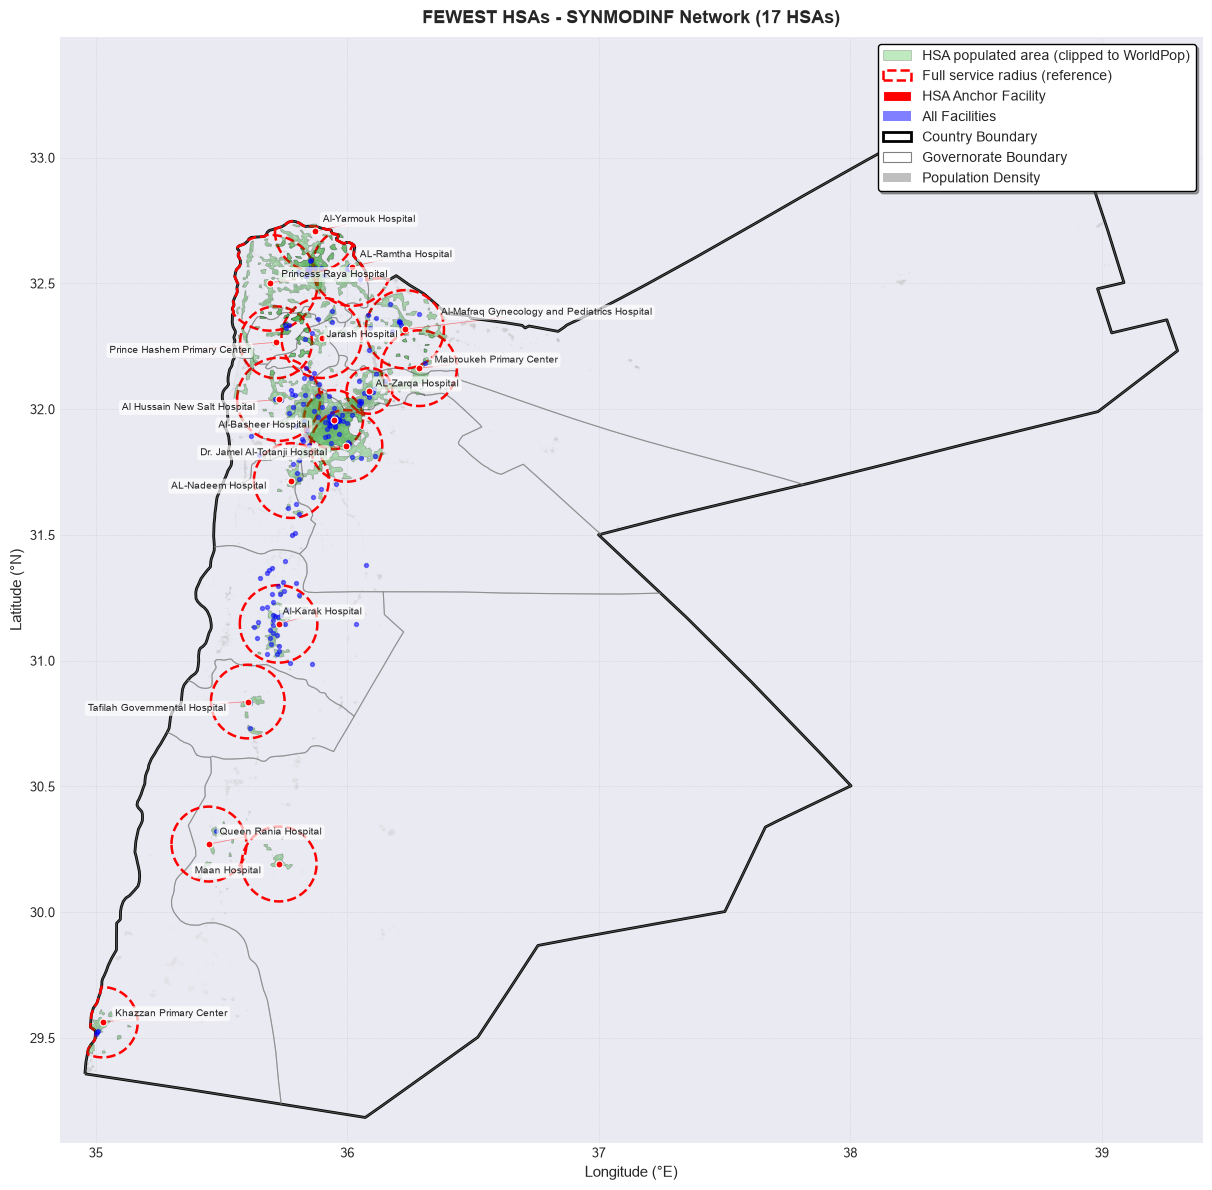


Creating map for FOOTPRINT HSAs...
  Using population-clipped polygons from SYNMODINF_footprint_hsas_v7.geojson
Saved: SYNMODINF_footprint_map_v7.png


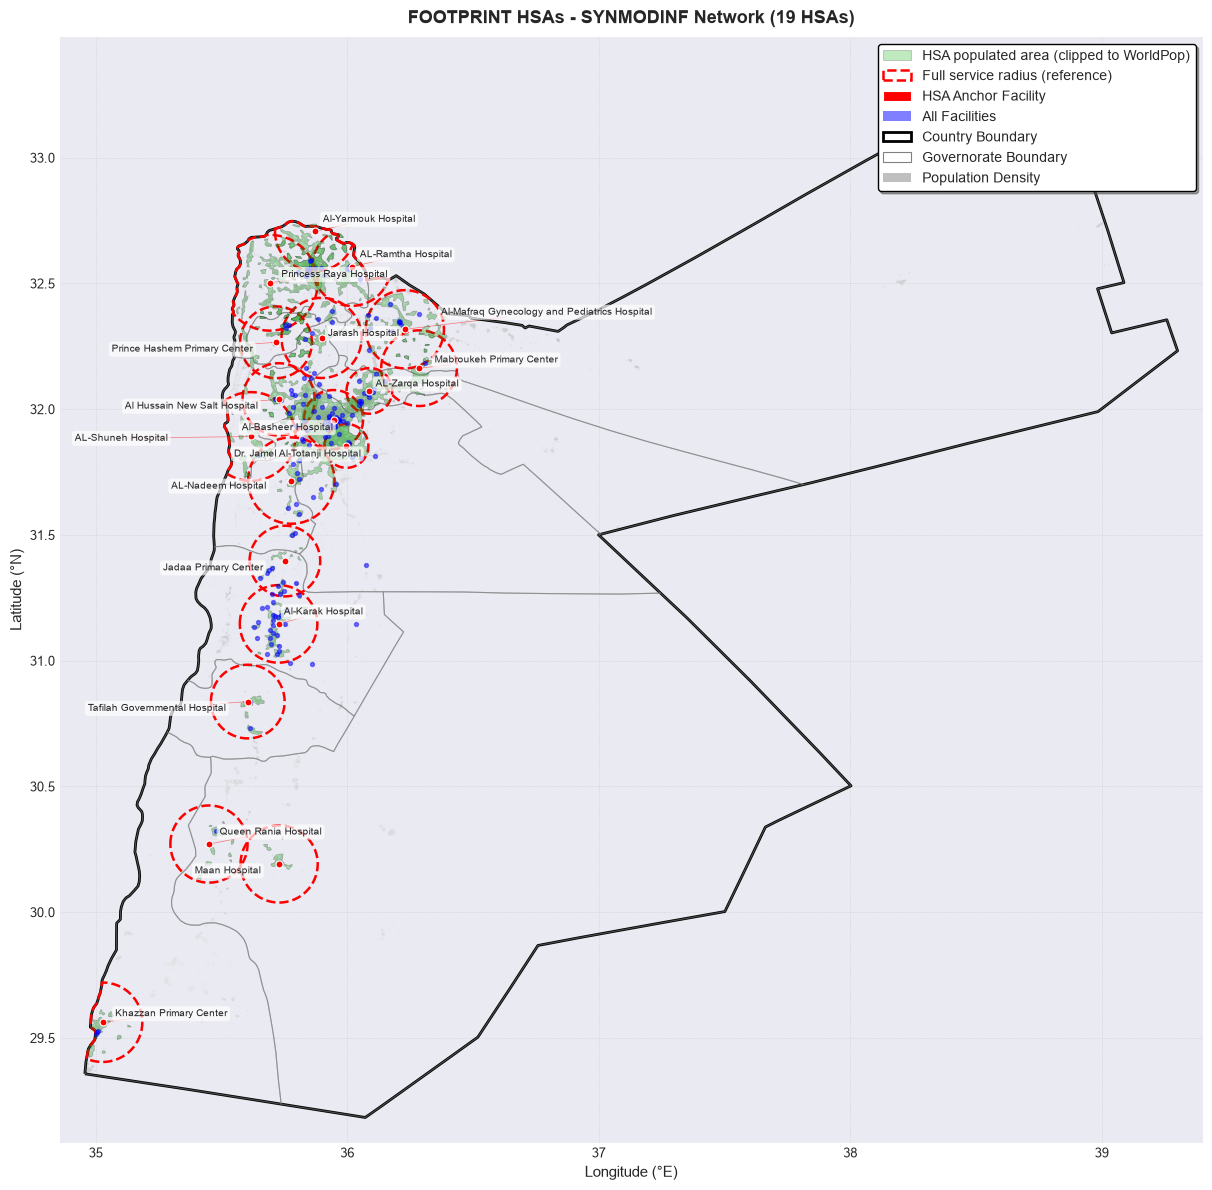


Creating map for DISTANCE HSAs...
  Using population-clipped polygons from SYNMODINF_distance_hsas_v7.geojson
Saved: SYNMODINF_distance_map_v7.png


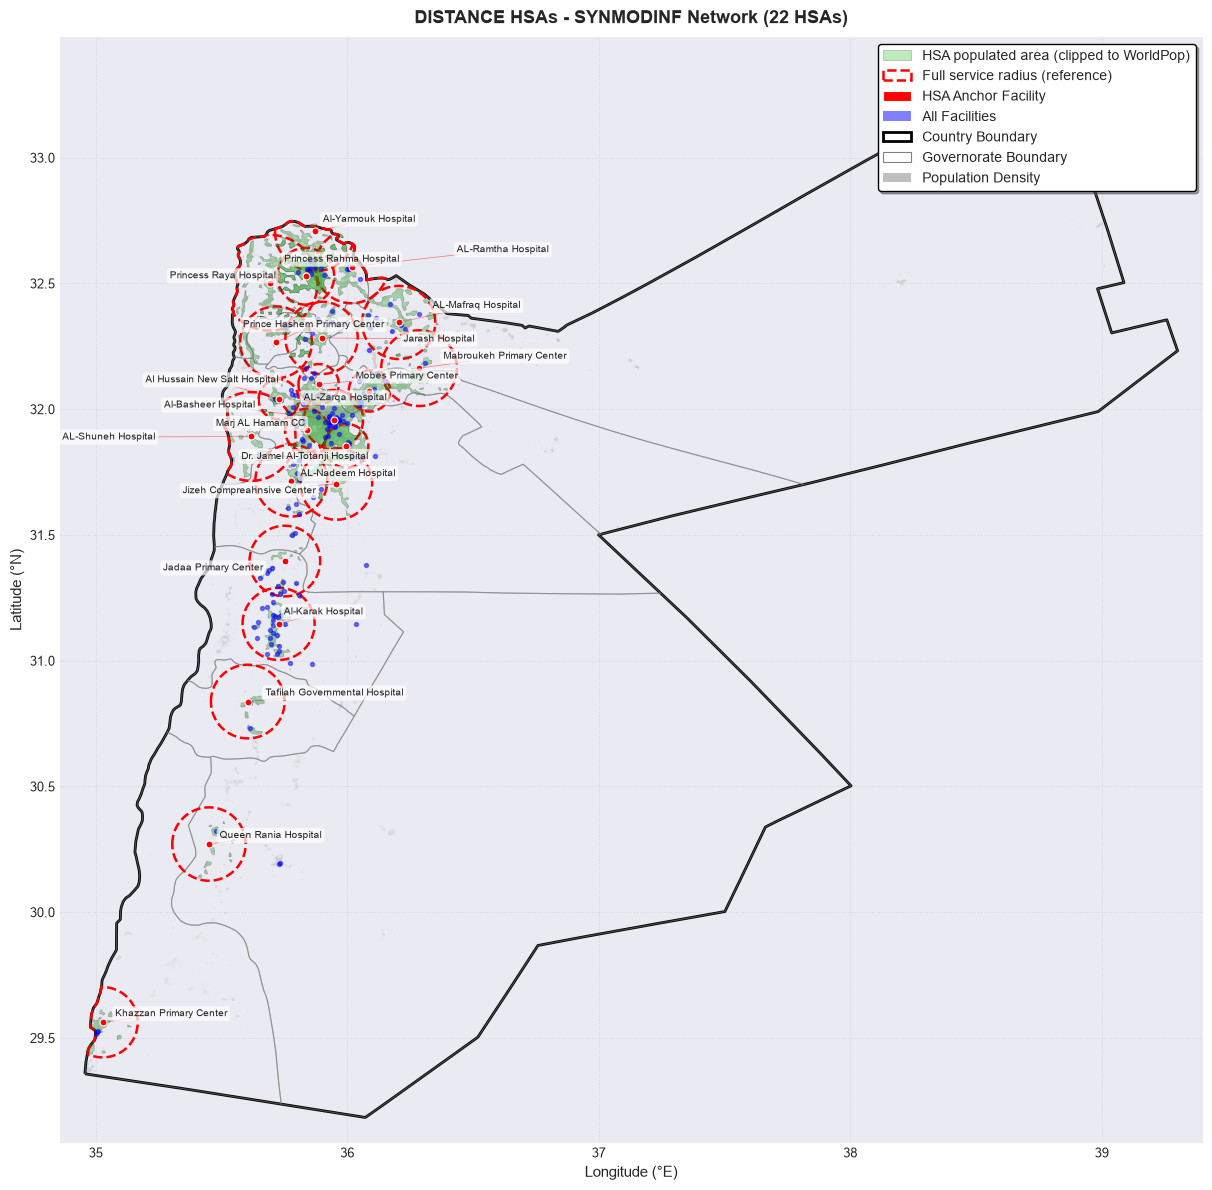


Creating map for GOVERNORATE TAU COVERAGE HSAs...
  Using population-clipped polygons from SYNMODINF_governorate_tau_coverage_hsas_v7.geojson
Saved: SYNMODINF_governorate_tau_coverage_map_v7.png


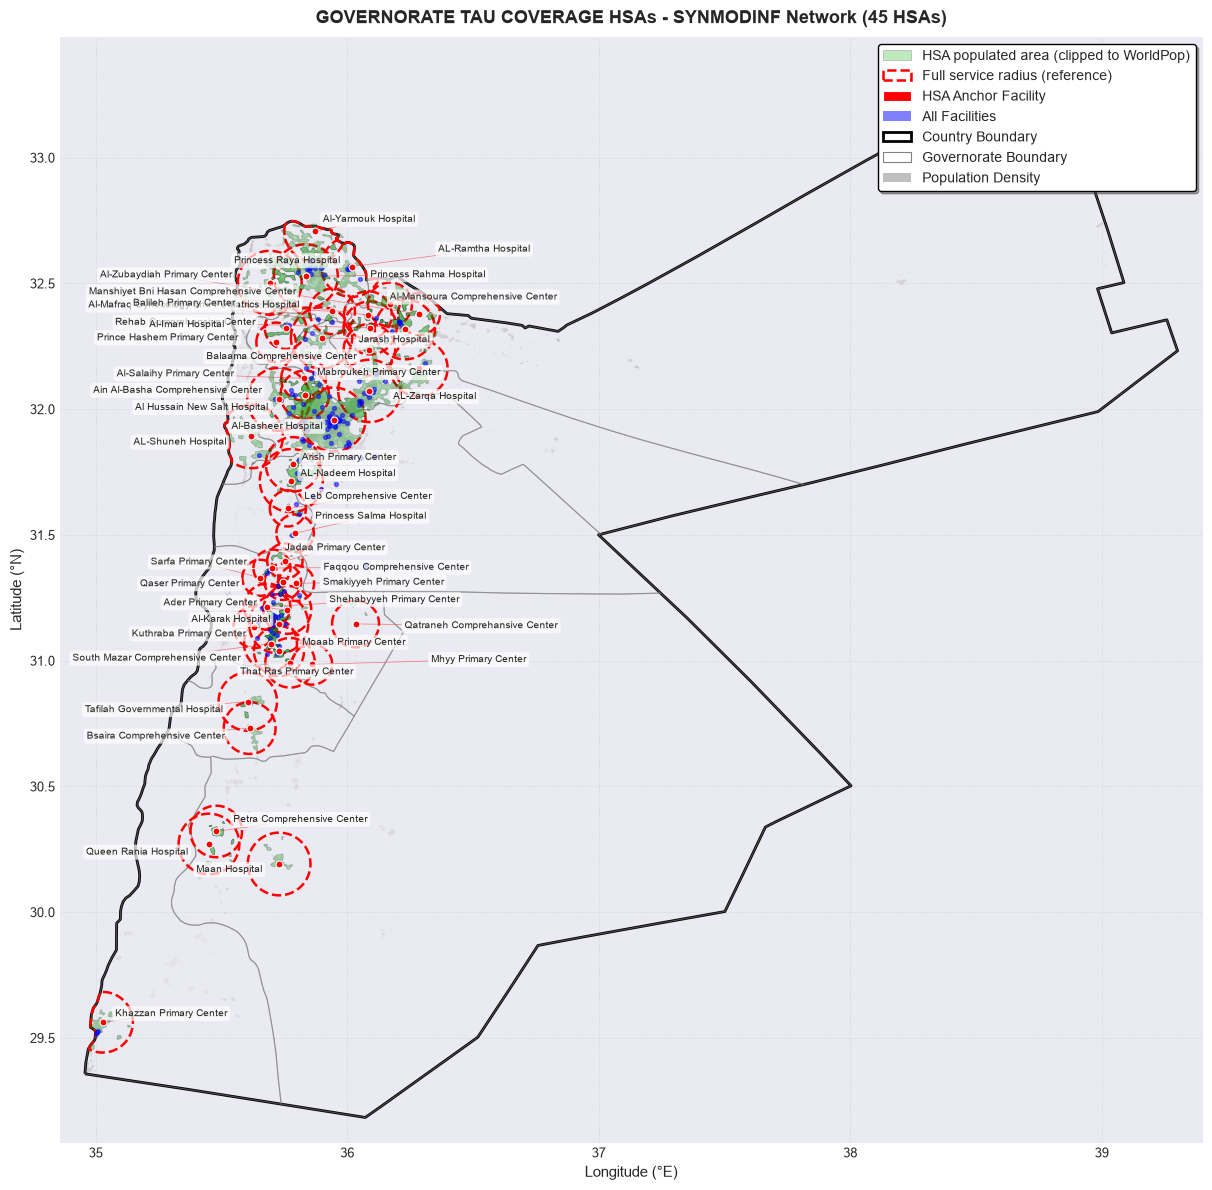


Creating map for GOVERNORATE FEWEST HSAs...
  Using population-clipped polygons from SYNMODINF_governorate_fewest_hsas_v7.geojson
Saved: SYNMODINF_governorate_fewest_map_v7.png


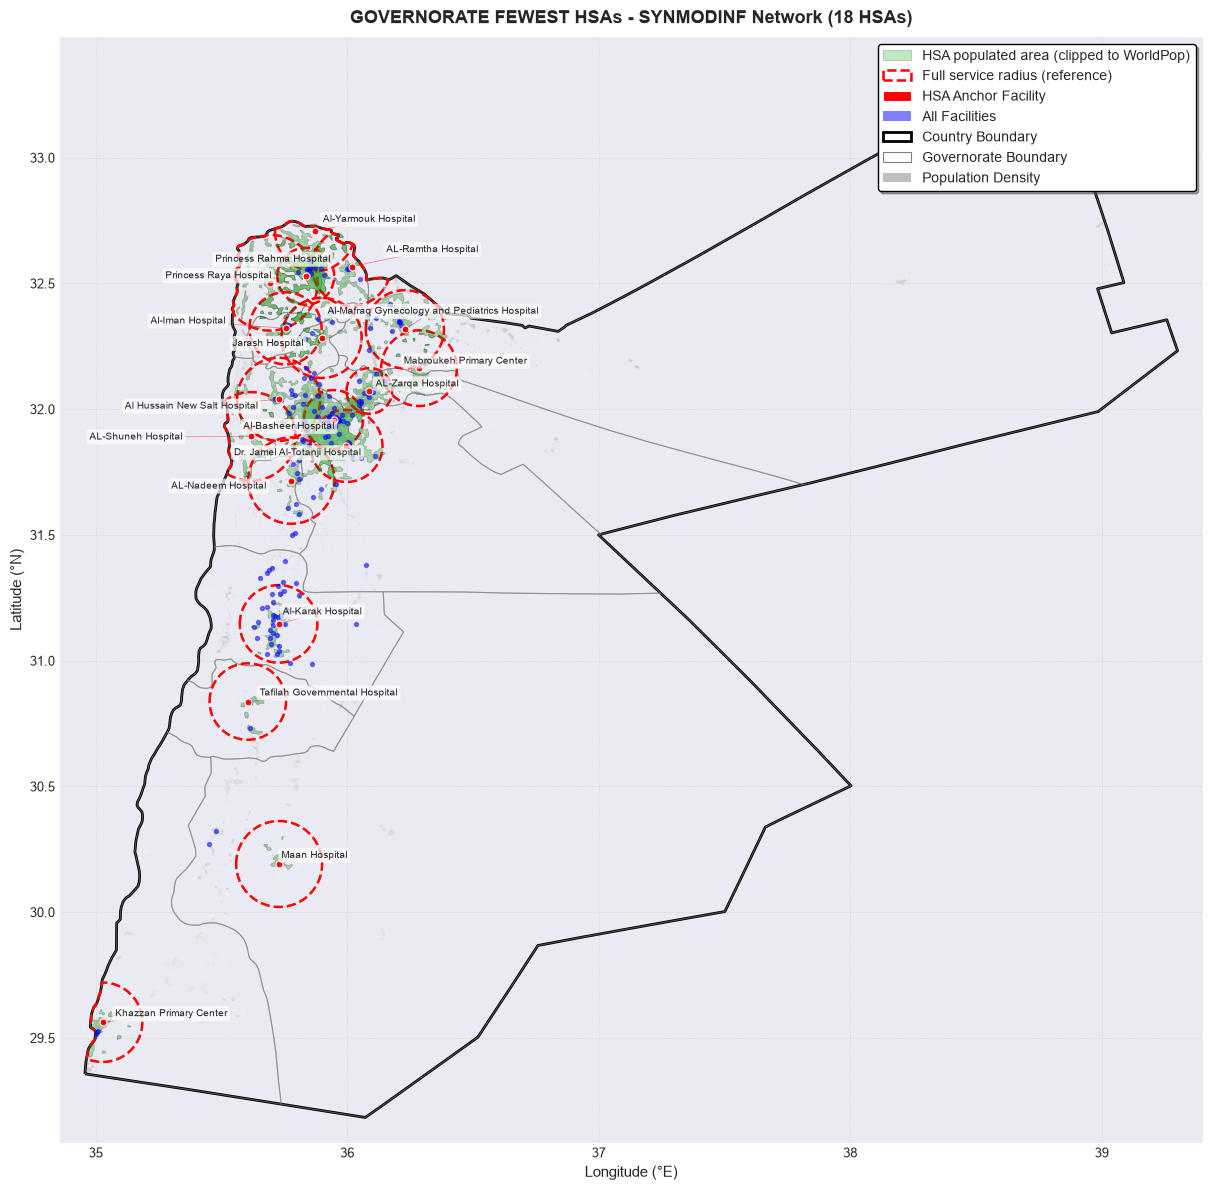


ALL MAPS CREATED SUCCESSFULLY

Saving GeoPackage: SYNMODINF_fewest_map_v7.gpkg
  hsa_boundaries: population-clipped (SYNMODINF_fewest_hsas_v7.geojson)
  Layers: hsa_circles, hsa_boundaries, hsa_anchors, all_facilities, country_boundary, governorates
  Saved: out/SYNMODINF_fewest_map_v7.gpkg

Saving GeoPackage: SYNMODINF_footprint_map_v7.gpkg
  hsa_boundaries: population-clipped (SYNMODINF_footprint_hsas_v7.geojson)
  Layers: hsa_circles, hsa_boundaries, hsa_anchors, all_facilities, country_boundary, governorates
  Saved: out/SYNMODINF_footprint_map_v7.gpkg

Saving GeoPackage: SYNMODINF_distance_map_v7.gpkg
  hsa_boundaries: population-clipped (SYNMODINF_distance_hsas_v7.geojson)
  Layers: hsa_circles, hsa_boundaries, hsa_anchors, all_facilities, country_boundary, governorates
  Saved: out/SYNMODINF_distance_map_v7.gpkg

Saving GeoPackage: SYNMODINF_governorate_tau_coverage_map_v7.gpkg
  hsa_boundaries: population-clipped (SYNMODINF_governorate_tau_coverage_hsas_v7.geojson)
  Layers: h

In [9]:
# ============================================================================
# CREATE MAPS FOR ALL MODES × ALL ALGORITHM VARIANTS (15 maps total)
# ============================================================================

import sys
if 'hsa_mapping' in sys.modules:
    del sys.modules["hsa_mapping"]
if 'hsa_mapping_working' in sys.modules:
    del sys.modules["hsa_mapping_working"]

from hsa_mapping_working import create_all_hsa_maps, save_hsa_geopackages

for ver in ['v6', 'v7', 'v8']:
    ver_results = {obj: data for (v, obj), data in all_version_results.items() if v == ver}
    if not ver_results:
        print(f"Skipping maps for {ver} — no results in all_version_results")
        continue

    print(f"\n{'='*60}")
    print(f"Creating maps for {ver} ({len(ver_results)} modes)...")
    print('='*60)

    create_all_hsa_maps(
        all_results=ver_results,
        network=NETWORK,
        data_dir=DATA_DIR,
        out_dir=OUT_DIR,
        algo_version=ver,
    )
    save_hsa_geopackages(
        all_results=ver_results,
        network=NETWORK,
        data_dir=DATA_DIR,
        out_dir=OUT_DIR,
        algo_version=ver,
    )

print("\nDone — 15 maps and 15 GeoPackages written to", OUT_DIR)


## Generate HSA Detail Tables

In [10]:
# ============================================================================
# HSA DETAIL TABLES - ALL MODES, ALL HSAS
# ============================================================================

from geopandas import sjoin
import rasterio
from rasterio.mask import mask as raster_mask
import pandas as pd


# Load all facilities once from climate CSV + diagnosis counts
# Facility climate is a shared input produced once by GEE Step A, before any
# delineation exists. Look in the run directory first, then out/, then data/ --
# the synthetic networks ship it there so the pipeline runs without an Earth
# Engine account. These features depend only on facility location.
climate_csv = OUT_DIR / f'{NETWORK}_Facilities_Climate_Features_with_clusters.csv'
if not climate_csv.exists():
    for _alt in (Path('out') / climate_csv.name, DATA_DIR / climate_csv.name):  # noqa: hardcode - out/ holds the canonical facility-climate master
        if _alt.exists():
            print(f"  Facility climate not in {OUT_DIR}; using {_alt}")
            climate_csv = _alt
            break
# Diagnosis counts path resolution: mode-aware when available, safe fallback when not.
mode_suffix = f"_{HSA_MODE}" if 'HSA_MODE' in globals() and HSA_MODE else ""
diag_candidates = []
if mode_suffix:
    diag_candidates.append(OUT_DIR / f'{NETWORK}{mode_suffix}_diagnosis_counts_pivot.csv')
diag_candidates.extend([
    OUT_DIR / f'{NETWORK}_diagnosis_counts_pivot.csv',
    OUT_DIR / f'{NETWORK}_footprint_diagnosis_counts_pivot.csv',
])

diagnosis_csv = next((c for c in diag_candidates if c.exists()), diag_candidates[0])

climate_df = pd.read_csv(climate_csv)
diagnosis_df = pd.read_csv(diagnosis_csv)

# Rename FacilityName to HealthFacility
if 'FacilityName' in climate_df.columns:
    climate_df['HealthFacility'] = climate_df['FacilityName']

# NORMALIZE WHITESPACE: Collapse multiple spaces to single space
climate_df['HealthFacility'] = climate_df['HealthFacility'].str.replace(r'\s+', ' ', regex=True).str.strip()
diagnosis_df['healthfacility'] = diagnosis_df['healthfacility'].str.replace(r'\s+', ' ', regex=True).str.strip()

# Merge
merged_df = climate_df.merge(
    diagnosis_df[['healthfacility', 'total_diagnoses']],
    left_on='HealthFacility',
    right_on='healthfacility',
    how='left'
)
merged_df['Total'] = merged_df['total_diagnoses'].fillna(0)

all_facilities = gpd.GeoDataFrame(
    merged_df,
    geometry=gpd.points_from_xy(merged_df['lon'], merged_df['lat']),
    crs='EPSG:4326'
).to_crs('EPSG:32637')


modes_to_process = {
    'fewest': 'FEWEST',
    'footprint': 'FOOTPRINT',
    'distance': 'DISTANCE',
    'governorate_tau_coverage': 'GOVERNORATE TAU COVERAGE',
    'governorate_fewest': 'GOVERNORATE FEWEST'
}


for mode_name, mode_label in modes_to_process.items():
    hsas_file = OUT_DIR / f'{NETWORK}_{mode_name}_hsas_{ALGO_VERSION}.geojson'

    if not hsas_file.exists():
        print(f"\nSkipping {mode_label} - file not found: {hsas_file.name}")
        continue

    hsas_gdf = gpd.read_file(hsas_file)
    hsas_utm = hsas_gdf.to_crs(all_facilities.crs)

    print(f"\n{'='*80}")
    print(f"{mode_label} - ALL {len(hsas_gdf)} HSAs")
    print('='*80)

    details = []

    for idx, row in hsas_utm.iterrows():
        anchor_volume = pd.to_numeric(row.get('Total', 0), errors='coerce')
        hsa_geom_utm = row.geometry
        if hsa_geom_utm is None or getattr(hsa_geom_utm, 'is_empty', False):
            print(f"  WARNING: Empty HSA geometry for {row.get('FacilityName', idx)}")
            continue

        radius_km = row.get('service_radius_km', row.get('initial_radius_km', 15.0))

        hsa_temp = gpd.GeoDataFrame([{'geometry': hsa_geom_utm}], crs=hsas_utm.crs)
        facilities_in_hsa = sjoin(all_facilities, hsa_temp, how='inner', predicate='intersects')

        total_hsa_volume = 0
        for fac_idx, fac_row in facilities_in_hsa.iterrows():
            fac_vol = pd.to_numeric(fac_row['Total'], errors='coerce')
            if not pd.isna(fac_vol):
                total_hsa_volume += fac_vol

        hsa_geom_latlon = gpd.GeoDataFrame(
            [{'geometry': hsa_geom_utm}],
            crs=hsas_utm.crs
        ).to_crs('EPSG:4326').geometry.iloc[0]

        try:
            with rasterio.open(config['pop_path']) as src:
                out_image, out_transform = raster_mask(src, [hsa_geom_latlon], crop=True, nodata=0)
                total_pop = float(out_image.sum())
        except Exception:
            total_pop = 0

        details.append({
            'HSA_Anchor': row['FacilityName'],
            'Anchor_Volume': anchor_volume,
            'Num_Facilities_in_HSA': len(facilities_in_hsa),
            'Total_HSA_Volume': total_hsa_volume,
            'HSA_Population': total_pop,
            'Service_Radius_km': radius_km,
            'Satellite_Bubbles': row.get('satellite_bubble_count', 0),
            'Bubble_Area_Added_km2': row.get('satellite_bubble_area_added_km2', 0.0),
            'Composite_Score': row.get('composite_score', 0)
        })

    detail_df = pd.DataFrame(details)
    print(detail_df.to_string(index=False))

    print(f"\nSummary Statistics:")
    print(f"  Total HSAs: {len(detail_df)}")
    print(f"  Total facilities across all HSAs: {detail_df['Num_Facilities_in_HSA'].sum()}")
    print(f"  Total HSA volume: {detail_df['Total_HSA_Volume'].sum():,.0f}")
    print(f"  Total population covered: {detail_df['HSA_Population'].sum():,.0f}")
    print(f"  Satellite bubbles: {pd.to_numeric(detail_df['Satellite_Bubbles'], errors='coerce').fillna(0).sum():.0f}")

print("\n" + "="*80)
print("HSA DETAIL TABLES COMPLETE")
print("="*80)


  Facility climate not in out; using data/SYNMODINF_Facilities_Climate_Features_with_clusters.csv

FEWEST - ALL 17 HSAs
                                  HSA_Anchor  Anchor_Volume  Num_Facilities_in_HSA  Total_HSA_Volume  HSA_Population  Service_Radius_km  Satellite_Bubbles  Bubble_Area_Added_km2  Composite_Score
                         Al-Basheer Hospital           3286                     38             22620    3.430042e+06          12.000000                  0                    0.0        42.026998
                      Princess Raya Hospital           2282                     11              8875    8.583258e+05          19.400122                  0                    0.0        15.357354
                Al Hussain New Salt Hospital           1134                     14              5784    9.068718e+05          16.884723                  0                    0.0         8.464826
                           AL-Zarqa Hospital           1050                     12              5465

In [11]:
# Generate / refresh this network's sanitation metadata from facility coordinates + JMP lookup
# Covers all facilities so the file stays valid for v6/v7/v8 anchor sets.
# No --out: the script names the file after the coordinates it read, so the INF
# and NCD copies coexist instead of overwriting each other.
import subprocess, sys
result = subprocess.run(
    [sys.executable, "generate_hsa_metadata.py",
     "--network", NETWORK],
    capture_output=False,
)
if result.returncode != 0:
    print("WARNING: generate_hsa_metadata.py failed — sanitation metadata not updated")

Reading:  /Users/sumedh/Desktop/SDSC/jordan-hsa-optimization/data/SYNMODINF_facility_coordinates.csv
JMP ref:  /Users/sumedh/Desktop/SDSC/jordan-hsa-optimization/data/jmp_2025_jordan_governorate.csv
Wrote 188 rows to /Users/sumedh/Desktop/SDSC/jordan-hsa-optimization/data/SYNMODINF_hsa_metadata.csv


In [12]:
# AUTO_NOTEBOOK_SUMMARY_V1
from pathlib import Path
from datetime import datetime
import os
import json

NOTEBOOK_NAME = "HSA_FINAL"
NETWORK = globals().get('NETWORK', os.environ.get('NETWORK', 'INF'))
HSA_MODE = globals().get('HSA_MODE', os.environ.get('HSA_MODE', ''))

suffix = f"{NETWORK}_{HSA_MODE}" if HSA_MODE else f"{NETWORK}"

out_root = Path(globals().get('OUT_DIR', globals().get('OUT_ROOT', os.environ.get('HSA_OUT_DIR', os.environ.get('PIPELINE_OUT_DIR', "out")))))
summary_dir = out_root / 'textresults'
summary_dir.mkdir(parents=True, exist_ok=True)
BOUNDARY_VERSION = globals().get('BOUNDARY_VERSION', os.environ.get('BOUNDARY_VERSION', os.environ.get('PIPELINE_VERSION', 'v7')))
summary_path = summary_dir / f"{NOTEBOOK_NAME}_{suffix}_{BOUNDARY_VERSION}_results.md"

files = [p for p in out_root.rglob('*') if p.is_file() and p.suffix.lower() in {'.csv', '.json', '.md', '.txt', '.png', '.pdf', '.geojson', '.parquet'}]
files.sort(key=lambda p: p.stat().st_mtime, reverse=True)
important = files[:120]

NL = "\n"

blocks = []
blocks.append(f"# Notebook Results: {NOTEBOOK_NAME}")

meta = [
    f"- Generated: {datetime.now().isoformat(timespec='seconds')}",
    f"- Network: {NETWORK}",
]
if HSA_MODE:
    meta.append(f"- HSA mode: {HSA_MODE}")
blocks.append(NL.join(meta))

file_lines = ['## Important Output Files', '']
for p in important:
    file_lines.append(f"- `{p}`")
blocks.append(NL.join(file_lines))

# The executed-cell-output section is appended by run_pipeline.py after the
# kernel exits. It cannot be produced here: at this point the current run's
# outputs exist only in kernel memory, and the .ipynb on disk still holds the
# previous run's, which is what this cell used to copy into the summary.

summary = (NL + NL).join(b for b in blocks if b and str(b).strip()) + NL
summary_path.write_text(summary)
print(f"Saved notebook summary: {summary_path}")


Saved notebook summary: out/textresults/HSA_FINAL_SYNMODINF_v7_results.md
